# 04 · Detección de pedidos anómalos (Isolation Forest)

**Pregunta de negocio 3:** ¿qué pedidos son sospechosos?

Datos: una fila por pedido (todos los estados), creada con `tabla_pedidos()` de `src/features.py`:
importe, número de líneas, unidades, la cantidad más alta de una línea, el precio cobrado frente al
de catálogo (máximo y mínimo entre sus líneas) y el importe por unidad.

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.
>
> **Regla del notebook:** la lista real de pedidos anómalos (`_verdad_anomalias.csv`) **solo** se usa
> en las secciones 7 y 8, marcadas como **EVALUACIÓN**. Las variables, la transformación, los
> hiperparámetros y el umbral se deciden antes y sin mirarla, como en una empresa real, donde esa
> lista no existe.

## 0. Configuración y carga

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import export_text

# El notebook se ejecuta desde notebooks/: src está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from features import tabla_pedidos  # noqa: E402

SEMILLA = 42
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
AZUL, NARANJA, VERDE_AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def num(valor, decimales=2):
    """1234.567 -> '1.234,57' (número en formato español, sin unidad)."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def pct(valor, decimales=1):
    """0.1234 -> '12,3 %'."""
    return f"{num(100 * valor, decimales)} %"


def guardar(fig, nombre):
    """Guarda la figura en docs/img/anomalias_<nombre>.png.

    metadata={"Software": None} quita la versión de matplotlib del PNG: con los mismos datos,
    el archivo es idéntico byte a byte entre ejecuciones.
    """
    fig.savefig(CARPETA_IMG / f"anomalias_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

In [2]:
pedidos = tabla_pedidos()

# Variables del modelo (las de identificación y las de texto quedan fuera)
VARIABLES = ["importe_total", "n_lineas", "unidades_totales", "max_cantidad_linea",
             "ratio_precio_max", "ratio_precio_min", "importe_por_unidad"]
ETIQUETAS = {
    "importe_total": "Importe del pedido (€)",
    "n_lineas": "Nº de líneas (productos distintos)",
    "unidades_totales": "Unidades totales",
    "max_cantidad_linea": "Máx. unidades en una línea",
    "ratio_precio_max": "Precio cobrado / catálogo (máx.)",
    "ratio_precio_min": "Precio cobrado / catálogo (mín.)",
    "importe_por_unidad": "Importe por unidad (€)",
}

print(f"Pedidos: {len(pedidos)} (todos los estados)")
print(f"Desde {pedidos['fecha_pedido'].min().date()} hasta {pedidos['fecha_pedido'].max().date()}")
print(pedidos["estado"].value_counts().to_string())
pedidos[VARIABLES].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(2)

Pedidos: 7297 (todos los estados)
Desde 2024-11-04 hasta 2026-10-31
estado
completado    6541
cancelado      391
devuelto       365


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
count,7297.00,7297.00,7297.00,7297.00,7297.00,7297.00,7297.00
mean,135.81,1.63,2.79,2.01,1.01,1.00,48.23
std,251.09,1.00,3.18,2.71,0.23,0.15,38.35
min,4.97,1.00,1.00,1.00,0.11,0.10,2.68
25%,44.08,1.00,1.00,1.00,1.00,1.00,25.32
50%,83.90,1.00,2.00,2.00,1.00,1.00,39.67
75%,167.71,2.00,4.00,2.00,1.00,1.00,58.92
99%,813.90,4.00,10.00,5.00,1.00,1.00,217.23
max,11730.42,12.00,59.00,59.00,9.58,8.96,572.90


In [3]:
# ¿Cuántos pedidos tienen alguna línea con un precio distinto al de catálogo?
# (se mira con un margen de 0,1 % por los redondeos de la limpieza al recalcular precios)
precio_distinto = ((pedidos["ratio_precio_max"] - 1).abs() > 0.001) | ((pedidos["ratio_precio_min"] - 1).abs() > 0.001)
print(f"Pedidos con alguna línea a un precio distinto del de catálogo: {precio_distinto.sum()} "
      f"({pct(precio_distinto.mean(), 2)})")
print(f"  por encima (ratio máx. > 1,001): {(pedidos['ratio_precio_max'] > 1.001).sum()}")
print(f"  por debajo (ratio mín. < 0,999): {(pedidos['ratio_precio_min'] < 0.999).sum()}")
asimetria = pedidos[VARIABLES].skew().rename("asimetría")
asimetria.round(2).to_frame().T

Pedidos con alguna línea a un precio distinto del de catálogo: 27 (0,37 %)
  por encima (ratio máx. > 1,001): 8
  por debajo (ratio mín. < 0,999): 19


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
asimetría,24.92,3.07,9.5,14.84,31.17,44.91,3.05


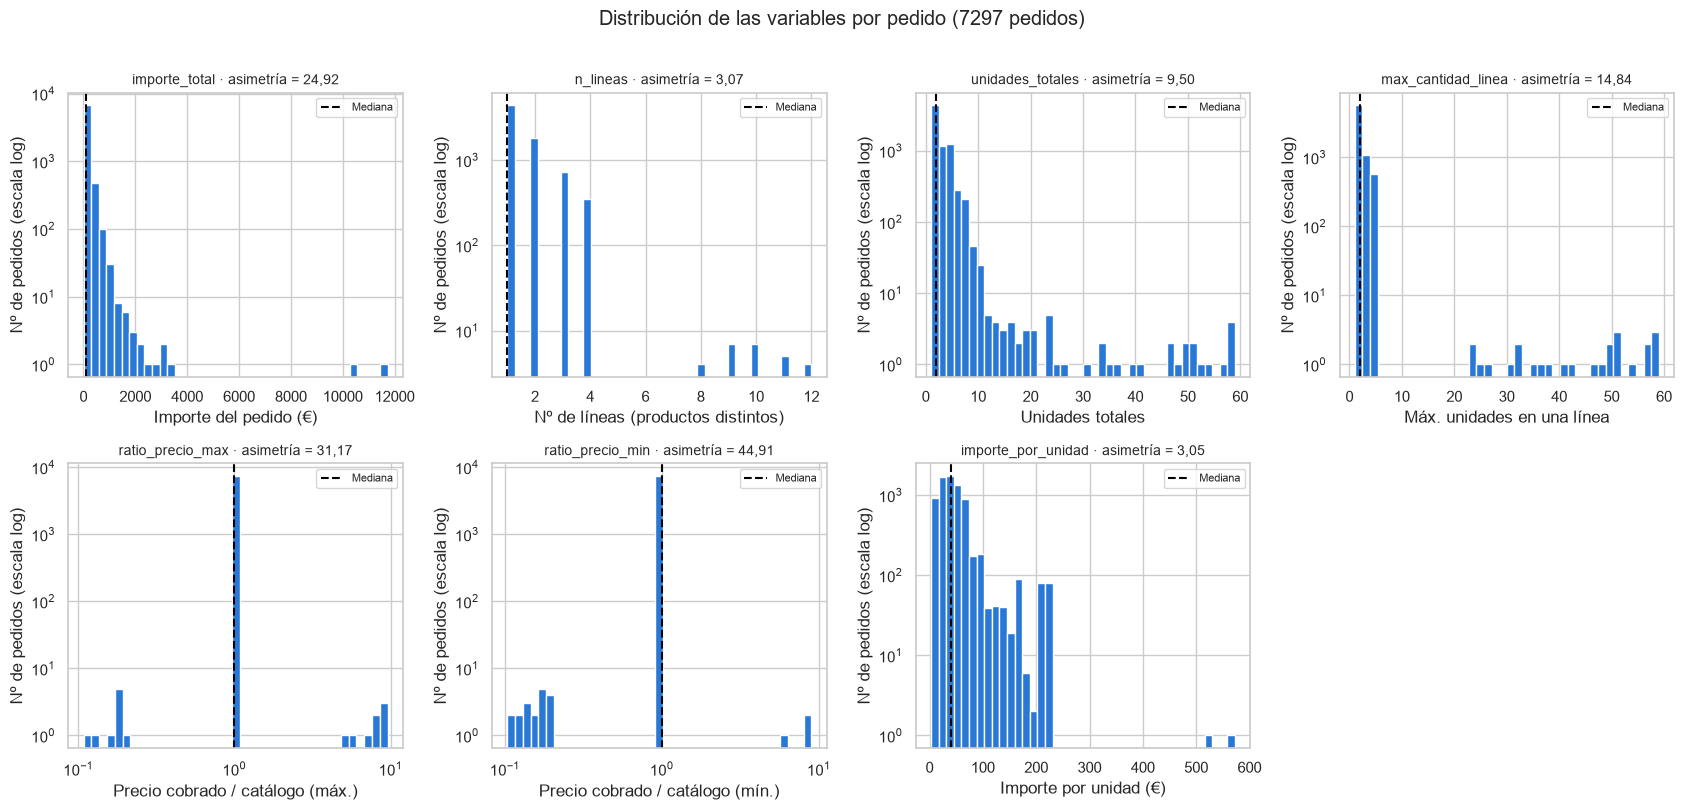

In [4]:
fig, ejes = plt.subplots(2, 4, figsize=(17, 8))
for ax, var in zip(ejes.flat, VARIABLES):
    datos = pedidos[var]
    if var.startswith("ratio"):
        # Los ratios se ven mejor en escala logarítmica: ×10 y ×0,1 quedan a la misma distancia de 1
        bins = np.logspace(np.log10(datos.min()), np.log10(datos.max()), 40)
        ax.set_xscale("log")
    else:
        bins = 40
    ax.hist(datos, bins=bins, color=AZUL, edgecolor="white")
    ax.axvline(datos.median(), color="black", linestyle="--", linewidth=1.5, label="Mediana")
    ax.set_yscale("log")  # escala log en el eje Y: si no, las colas (pocos pedidos) no se ven
    ax.set_title(f"{var} · asimetría = {num(datos.skew())}", fontsize=10)
    ax.set_xlabel(ETIQUETAS[var])
    ax.set_ylabel("Nº de pedidos (escala log)")
    ax.legend(fontsize=8)
ejes.flat[-1].axis("off")
fig.suptitle(f"Distribución de las variables por pedido ({len(pedidos)} pedidos)", y=1.01)
fig.tight_layout()
guardar(fig, "distribuciones")
plt.show()

**Lectura:** hay 7.297 pedidos (6.541 completados, 391 cancelados y 365 devueltos), del 2024-11-04 al
2026-10-31. Todas las variables tienen cola larga a la derecha: el importe mediano es 83,90 € y el
máximo 11.730,42 €; la mediana de unidades es 2 y el máximo 59; el 99 % de los pedidos tiene como mucho
4 líneas, pero el máximo es 12. Los **ratios de precio valen 1 en casi todos los pedidos**: solo 27
(0,37 %) tienen alguna línea a un precio distinto del de catálogo, 8 por encima y 19 por debajo. Por
eso su asimetría es enorme (31,17 y 44,91): son variables casi constantes con unos pocos valores muy
lejanos.

## 1. Por qué no basta con IQR

El método de la S4: para cada variable, un pedido es "outlier" si supera **Q3 + 1,5·IQR**
(IQR = Q3 − Q1). Se aplica a una variable cada vez y el pedido se marca si **cualquiera** de las
variables supera su límite.

In [5]:
q1 = pedidos[VARIABLES].quantile(0.25)
q3 = pedidos[VARIABLES].quantile(0.75)
limite_iqr = q3 + 1.5 * (q3 - q1)
supera = pedidos[VARIABLES] > limite_iqr
marcado_iqr = supera.any(axis=1)

resumen_iqr = pd.DataFrame({
    "Q1": q1, "Q3": q3, "límite Q3 + 1,5·IQR": limite_iqr,
    "pedidos que lo superan": supera.sum(),
    "% de pedidos": (100 * supera.mean()).round(2),
})
print(f"Pedidos marcados por IQR (alguna variable): {marcado_iqr.sum()} de {len(pedidos)} "
      f"({pct(marcado_iqr.mean())})")
print(f"Al mes: {num(marcado_iqr.sum() / pedidos['fecha_pedido'].dt.to_period('M').nunique(), 1)} pedidos de media")
print(f"Pedidos con precio por DEBAJO del catálogo (ratio mín. < 0,999): {(pedidos['ratio_precio_min'] < 0.999).sum()}; "
      f"de ellos marcados por IQR solo por el ratio: "
      f"{(supera['ratio_precio_min'] & (pedidos['ratio_precio_min'] < 0.999)).sum()}")
resumen_iqr.round(2)

Pedidos marcados por IQR (alguna variable): 1298 de 7297 (17,8 %)
Al mes: 54,1 pedidos de media
Pedidos con precio por DEBAJO del catálogo (ratio mín. < 0,999): 19; de ellos marcados por IQR solo por el ratio: 0


,Q1,Q3,"límite Q3 + 1,5·IQR",pedidos que lo superan,% de pedidos
importe_total,44.08,167.71,353.16,469,6.43
n_lineas,1.00,2.00,3.50,380,5.21
unidades_totales,1.00,4.00,8.50,123,1.69
max_cantidad_linea,1.00,2.00,3.50,603,8.26
ratio_precio_max,1.00,1.00,1.00,8,0.11
ratio_precio_min,1.00,1.00,1.00,3,0.04
importe_por_unidad,25.32,58.92,109.31,389,5.33


In [6]:
# ¿Cuántas variables supera cada pedido marcado?
n_variables = supera.sum(axis=1)
print(n_variables[marcado_iqr].value_counts().sort_index().rename("pedidos").to_string())

# Ejemplo del problema: pedidos marcados que no se salen del percentil 99 en líneas ni en unidades
# por línea, y con el precio de catálogo (P99 de la sección 0: 4 líneas y 5 unidades por línea)
p99 = pedidos[["n_lineas", "max_cantidad_linea"]].quantile(0.99)
normales_marcados = marcado_iqr & (pedidos["n_lineas"] <= p99["n_lineas"]) \
    & (pedidos["max_cantidad_linea"] <= p99["max_cantidad_linea"]) & ~precio_distinto
print(f"\nPedidos marcados con ≤ {p99['n_lineas']:.0f} líneas, ≤ {p99['max_cantidad_linea']:.0f} unidades por línea "
      f"(los percentiles 99) y precio de catálogo: {normales_marcados.sum()} "
      f"({pct(normales_marcados.sum() / marcado_iqr.sum())} de los marcados)")

1    836
2    291
3    130
4     38
5      3

Pedidos marcados con ≤ 4 líneas, ≤ 5 unidades por línea (los percentiles 99) y precio de catálogo: 1236 (95,2 % de los marcados)


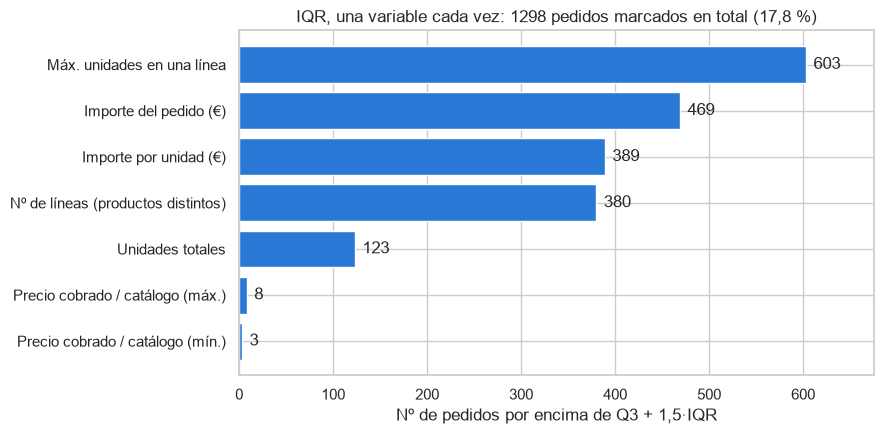

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cuenta = supera.sum().sort_values()
ax.barh([ETIQUETAS[v] for v in cuenta.index], cuenta.values, color=AZUL)
for i, valor in enumerate(cuenta.values):
    ax.text(valor + 8, i, str(valor), va="center")
ax.set_xlabel("Nº de pedidos por encima de Q3 + 1,5·IQR")
ax.set_title(f"IQR, una variable cada vez: {marcado_iqr.sum()} pedidos marcados en total "
             f"({pct(marcado_iqr.mean())})")
ax.set_xlim(0, cuenta.max() * 1.12)
fig.tight_layout()
guardar(fig, "iqr")
plt.show()

**Lectura:** IQR marca **1.298 pedidos (17,8 %)**, 54,1 al mes de media. Tres problemas:

1. **Cuando Q1 y Q3 están juntos, el límite es tan bajo que lo normal sale "outlier".** Q1 = 1 y Q3 = 2
   en líneas y en unidades por línea, así que el límite es 3,5: un pedido con 4 líneas o con 4 unidades
   de un producto ya se marca. Solo por eso salen 380 y 603 pedidos (5,21 % y 8,26 %). El 95,2 % de los
   marcados (1.236) no se sale del percentil 99 en líneas (4) ni en unidades por línea (5) y tiene el
   precio de catálogo.
2. **Solo mira hacia arriba.** En los ratios, Q1 = Q3 = 1 y el límite es 1: cualquier precio por encima
   del catálogo se marca (8 pedidos), pero los 19 pedidos con precio por debajo del catálogo no se marcan
   nunca por el ratio (0). Un descuento del 90 % es tan sospechoso como un sobreprecio ×10.
3. **Mira cada variable por separado.** 836 de los marcados lo están por una sola variable. IQR no ve
   combinaciones: un pedido de 4 líneas con productos caros es más raro que uno de 4 líneas baratas,
   pero para IQR son iguales. Isolation Forest mira todas las variables a la vez.

## 2. Isolation Forest

### La idea: aislar con cortes aleatorios

Un **árbol de aislamiento** coge una variable al azar y hace un corte en un valor al azar entre su
mínimo y su máximo. Repite con cada trozo hasta que cada punto queda solo (o hasta una profundidad
máxima). Un punto **raro** está lejos de los demás, así que un corte al azar lo separa enseguida:
**las anomalías se aíslan con pocos cortes**. Un punto normal está rodeado de otros parecidos y
necesita muchos cortes.

Un solo árbol es muy aleatorio, así que se hacen muchos (un "bosque") y se promedia el número de
cortes de cada punto: **h(x)**.

### La conexión con el ejercicio de clase (puntos A–E)

En clase hicimos árboles a mano con 5 puntos y calculamos la puntuación:

$$s(x, n) = 2^{-\dfrac{E[h(x)]}{c(n)}}, \qquad c(n) = 2\,H(n-1) - \frac{2(n-1)}{n}, \qquad H(i) \approx \ln(i) + 0{,}5772$$

- **h(x)** es la profundidad de x: el número de cortes hasta que queda solo. **E[h(x)]** es su media en
  todos los árboles.
- **c(n)** es el número medio de cortes que necesita un punto cualquiera en un árbol de n puntos.
  Sirve para normalizar: con 5 puntos, 2 cortes es poco; con 256, 2 cortes es poquísimo.
- Si h(x) es mucho menor que c(n), **s se acerca a 1** → anomalía. Si h(x) ≈ c(n), **s ≈ 0,5** → normal.
- **Umbral de clase: s > 0,5 → anomalía.**

**Los datos de clase:** A(1, 2), B(2, 3), C(3, 4), D(4, 5) y E(10, 10). En los 4 árboles hechos a mano,
E se aísla con el primer corte en los árboles 1, 2 y 3, y con el segundo en el árbol 4. Los demás puntos
tienen profundidades medias entre 2,5 y 3,5.

In [8]:
def c(n):
    """Número medio de cortes para aislar un punto en un árbol de n puntos (fórmula de clase)."""
    n = np.asarray(n, dtype=float)
    resultado = np.zeros_like(n)
    resultado[n == 2] = 1.0
    mayor = n > 2
    resultado[mayor] = 2 * (np.log(n[mayor] - 1) + np.euler_gamma) - 2 * (n[mayor] - 1) / n[mayor]
    return resultado


def puntuacion_clase(h_media, n):
    """s = 2^(-E[h] / c(n))."""
    return 2 ** (-np.asarray(h_media, dtype=float) / c(n))


puntos = pd.DataFrame({"x": [1, 2, 3, 4, 10], "y": [2, 3, 4, 5, 10]}, index=list("ABCDE"), dtype=float)
c5 = c(5).item()
print(f"c(5) = {num(c5, 3)} cortes de media para un punto cualquiera de un árbol de 5 puntos")

# Profundidad de E en mis 4 árboles hechos a mano: primer corte en los árboles 1, 2 y 3; segundo en el 4
profundidades_E = [1, 1, 1, 2]
h_E = np.mean(profundidades_E)
# Los demás puntos (A-D) tienen profundidades medias entre 2,5 y 3,5
h_resto_min, h_resto_max = 2.5, 3.5

tabla_mano = pd.DataFrame({
    "E[h(x)]": [h_E, h_resto_min, h_resto_max],
    "E[h] / c(5)": np.round([h_E / c5, h_resto_min / c5, h_resto_max / c5], 3),
    "s = 2^(−E[h]/c(5))": puntuacion_clase([h_E, h_resto_min, h_resto_max], 5).round(3),
}, index=["E", "A–D (profundidad 2,5)", "A–D (profundidad 3,5)"])
tabla_mano["¿anomalía? (s > 0,5)"] = tabla_mano["s = 2^(−E[h]/c(5))"] > 0.5

# Comprobación de los valores de clase
assert round(c5, 3) == 2.327
assert h_E == 1.25 and round(puntuacion_clase(h_E, 5).item(), 3) == 0.689
s_resto = puntuacion_clase([h_resto_min, h_resto_max], 5)
# Con profundidad 3,5 sale 0,353 y con 2,5 sale 0,475: los dos dentro del rango de clase (0,35-0,48)
assert 0.35 <= s_resto.min() and s_resto.max() <= 0.48
print(f"Valores de clase comprobados: c(5) ≈ 2,327, s(E) = 0,689 y A–D entre {num(s_resto.min(), 3)} "
      f"y {num(s_resto.max(), 3)} (rango de clase: 0,35-0,48)")
tabla_mano

c(5) = 2,327 cortes de media para un punto cualquiera de un árbol de 5 puntos
Valores de clase comprobados: c(5) ≈ 2,327, s(E) = 0,689 y A–D entre 0,353 y 0,475 (rango de clase: 0,35-0,48)


,E[h(x)],E[h] / c(5),s = 2^(−E[h]/c(5)),"¿anomalía? (s > 0,5)"
E,1.25,0.537,0.689,True
"A–D (profundidad 2,5)",2.50,1.074,0.475,False
"A–D (profundidad 3,5)",3.50,1.504,0.353,False


### Los mismos puntos con scikit-learn

scikit-learn hace lo mismo con 300 árboles aleatorios. Abajo se recorre cada árbol, se calcula h(x) a
mano y se comprueba que la s de la fórmula de clase coincide con lo que devuelve scikit-learn. Sus
números no son los de clase (son otros árboles, al azar, y muchos más), pero la conclusión es la misma.

In [9]:
iso_clase = IsolationForest(n_estimators=300, random_state=SEMILLA).fit(puntos)

# Uno de los 300 árboles, como los de clase: qué corte hace en cada nodo
print("Árbol nº 1 del bosque de scikit-learn:")
print(export_text(iso_clase.estimators_[0], feature_names=list(puntos.columns)))

# h(x) de cada punto a partir de los árboles de scikit-learn: nº de cortes hasta su hoja
# + c(nº de puntos que quedan en la hoja). Ese último término estima los cortes que faltarían:
# los árboles de scikit-learn se paran a una profundidad de log2(n).
X_puntos = puntos.to_numpy()
cortes_totales = np.zeros(len(puntos))
for arbol, columnas in zip(iso_clase.estimators_, iso_clase.estimators_features_):
    X_arbol = X_puntos[:, columnas]  # cada árbol puede ver las columnas en otro orden
    hojas = arbol.apply(X_arbol)
    cortes = np.asarray(arbol.decision_path(X_arbol).sum(axis=1)).ravel() - 1
    cortes_totales += cortes + c(arbol.tree_.n_node_samples[hojas])
h_media = cortes_totales / len(iso_clase.estimators_)
s_sklearn_mano = puntuacion_clase(h_media, iso_clase.max_samples_)

tabla_clase = pd.DataFrame({
    "x": puntos["x"], "y": puntos["y"],
    "h(x) medio (300 árboles)": h_media.round(3),
    "s con la fórmula de clase": s_sklearn_mano.round(4),
    "-score_samples (sklearn)": (-iso_clase.score_samples(puntos)).round(4),
    "decision_function": iso_clase.decision_function(puntos).round(4),
    "¿anomalía? (s > 0,5)": s_sklearn_mano > 0.5,
}, index=puntos.index)
assert np.allclose(s_sklearn_mano, -iso_clase.score_samples(puntos))
print("offset_ con contamination='auto':", iso_clase.offset_)
tabla_clase

Árbol nº 1 del bosque de scikit-learn:
|--- y <= 5.84
|   |--- y <= 4.54
|   |   |--- y <= 2.33
|   |   |   |--- value: [0.37]
|   |   |--- y >  2.33
|   |   |   |--- value: [0.84]
|   |--- y >  4.54
|   |   |--- value: [0.60]
|--- y >  5.84
|   |--- value: [0.16]



offset_ con contamination='auto': -0.5


,x,y,h(x) medio (300 árboles),s con la fórmula de clase,-score_samples (sklearn),decision_function,"¿anomalía? (s > 0,5)"
A,1.0,2.0,2.457,0.4811,0.4811,0.0189,False
B,2.0,3.0,3.213,0.3840,0.3840,0.1160,False
C,3.0,4.0,3.333,0.3705,0.3705,0.1295,False
D,4.0,5.0,2.840,0.4292,0.4292,0.0708,False
E,10.0,10.0,1.413,0.6564,0.6564,-0.1564,True


**Relación entre scikit-learn y la puntuación de clase** (comprobado arriba con `assert`):

| scikit-learn | Fórmula de clase | Cómo se lee |
|---|---|---|
| `score_samples(X)` | **−s** | Cambia el signo para que "más bajo = más raro" (convenio de sklearn) |
| `decision_function(X)` | −s − `offset_` | Con `contamination="auto"`, `offset_` = −0,5, así que es **0,5 − s**: negativo ⇔ s > 0,5 |
| `predict(X)` | −1 si s > 0,5, 1 si no | Es el **umbral de 0,5 de clase** |

En el resto del notebook se usa **puntuación = −`score_samples`**, es decir, la **s de clase**:
entre 0 y 1, y **cuanto más alta, más sospechoso**.

**Con tus árboles hechos a mano:** E se aísla de media en **1,25 cortes** (1, 1, 1 y 2), poco más de
la mitad de c(5) = 2,327. Así, E[h]/c(5) = 0,537 y **s = 2^(−0,537) = 0,689 > 0,5 → anomalía**. A–D, con
2,5–3,5 cortes de media, quedan entre **0,353 y 0,475**, por debajo de 0,5: normales. (Con 2,5 cortes
sale 0,4749: redondeado es 0,47, dentro del rango 0,35–0,48 de clase.)

**Con scikit-learn** (300 árboles al azar con los mismos 5 puntos), E necesita 1,413 cortes y puntúa
0,656; A–D, entre 0,371 y 0,481. Los números cambian porque los árboles son otros y son muchos más,
pero la conclusión es la misma: **solo E pasa de 0,5**. En el árbol nº 1 se ve como en tus árboles 1–3:
el primer corte (y ≤ 5,84) ya deja a E solo.

### El pipeline

1. **Transformación logarítmica** (`ColumnTransformer`):
   - `np.log1p` = log(1 + x) en importe, líneas, unidades, máx. unidades por línea e importe por
     unidad. Son variables con cola larga a la derecha (asimetría entre 3 y 25, sección 0). Isolation
     Forest corta en un valor **al azar entre el mínimo y el máximo**: sin log, casi todos los cortes
     caen en la zona vacía de la cola (de 20 a 59 unidades, por ejemplo) y casi ninguno separa 1, 2
     o 5 unidades, que es donde está la mayoría. Con el log, el rango se reparte mejor.
   - `np.log` (sin el +1) en los dos **ratios de precio**. Un ratio es una multiplicación: ×10 y ×0,1
     son "igual de raros". En escala normal, ×0,1 está a 0,9 de 1 y ×10 está a 9: los cortes al azar
     casi nunca caerían entre 0,1 y 1 y los precios bajos serían muy difíciles de aislar. Con el log,
     log(10) = 2,3 y log(0,1) = −2,3: **simétricos**. Se puede usar `log` sin el +1 porque el ratio es
     siempre > 0 (el esquema obliga a precio > 0).
2. **`StandardScaler`**: **no hace falta** en Isolation Forest. Cada corte se elige entre el mínimo y
   el máximo de **una sola variable**, así que cambiar su escala (restar la media y dividir por la
   desviación) mueve los cortes en la misma proporción y los árboles separan exactamente los mismos
   pedidos. Es lo contrario de K-Means o KNN, que usan distancias y sí lo necesitan. Abajo se comprueba
   que la puntuación con y sin él es idéntica. Se deja en el pipeline porque no cambia nada y deja los
   datos listos para el PCA de la sección 5, que sí necesita la misma escala en todas las variables.
3. **`IsolationForest(n_estimators=300, random_state=42)`**: 300 árboles (el valor por defecto es
   100; con más árboles la puntuación media varía menos de una ejecución a otra). Cada árbol usa
   256 pedidos al azar (`max_samples="auto"`), lo habitual en Isolation Forest: con pocos puntos, los
   normales no "tapan" a las anomalías.

Se usan funciones de numpy (`np.log1p`, `np.log`) y no funciones propias del notebook para que el
`.joblib` se pueda cargar desde otro programa (lo mismo que en la S7).

In [10]:
VARIABLES_LOG1P = ["importe_total", "n_lineas", "unidades_totales", "max_cantidad_linea", "importe_por_unidad"]
VARIABLES_RATIO = ["ratio_precio_max", "ratio_precio_min"]
assert sorted(VARIABLES_LOG1P + VARIABLES_RATIO) == sorted(VARIABLES)


def crear_pipeline(log1p, ratios, semilla=SEMILLA, escalar=True):
    """Transformación log -> (StandardScaler) -> IsolationForest. Se reutiliza en la estabilidad y la ablación."""
    transformaciones = [("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), log1p)]
    if ratios:
        transformaciones.append(("log", FunctionTransformer(np.log, feature_names_out="one-to-one"), ratios))
    pasos = [("log", ColumnTransformer(transformaciones))]
    if escalar:
        pasos.append(("escalar", StandardScaler()))
    pasos.append(("iforest", IsolationForest(n_estimators=300, random_state=semilla)))
    return Pipeline(pasos)


def puntuar(pipeline, datos):
    """Puntuación de clase s = -score_samples: entre 0 y 1, más alta = más sospechoso."""
    return -pipeline.score_samples(datos)


pipeline = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO).fit(pedidos[VARIABLES])
pedidos["puntuacion"] = puntuar(pipeline, pedidos[VARIABLES])

# ¿Hace falta el StandardScaler? Mismo modelo sin él:
sin_escalar = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO, escalar=False).fit(pedidos[VARIABLES])
diferencia = np.abs(puntuar(sin_escalar, pedidos[VARIABLES]) - pedidos["puntuacion"]).max()
print(f"Diferencia máxima de puntuación con y sin StandardScaler: {diferencia:.2e}")

print(f"\nPuntuación: mínimo {num(pedidos['puntuacion'].min(), 3)}, mediana {num(pedidos['puntuacion'].median(), 3)}, "
      f"máximo {num(pedidos['puntuacion'].max(), 3)}")
pedidos["puntuacion"].describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(3).to_frame().T

Diferencia máxima de puntuación con y sin StandardScaler: 0.00e+00

Puntuación: mínimo 0,401, mediana 0,448, máximo 0,752


,count,mean,std,min,50%,75%,90%,99%,max
puntuacion,7297.0,0.464,0.057,0.401,0.448,0.496,0.551,0.641,0.752


**Lectura:** la puntuación va de 0,401 a 0,752, con mediana 0,448: la mayoría de los pedidos está por
debajo de 0,5, es decir, se aísla con más cortes que la media (normal). Solo el 1 % pasa de 0,641. La
diferencia máxima con y sin `StandardScaler` es 0: confirma que el escalado no afecta a Isolation
Forest.

## 3. Umbral a partir de la distribución de las puntuaciones

El modelo ordena los pedidos de más a menos sospechoso, pero **no dice dónde cortar**. El equipo puede
revisar a mano **como mucho 50 pedidos al mes**. Eso es un **tope, no un objetivo**: si se llenaran
siempre las 50 revisiones (1.200 en 24 meses, el 16 % de los pedidos), la mayoría serían pedidos
normales, porque los pedidos raros de verdad son pocos.

Por eso el umbral se busca **en la forma de las puntuaciones**: ¿a partir de qué puntuación un pedido
es claramente distinto del resto? Se comparan varios criterios. Ninguno usa la verdad ni el 1 % que
plantó el generador: en una empresa real esos datos no existen.

| Criterio | Idea |
|---|---|
| **Codo** de la curva de puntuaciones ordenadas | Al ordenarlas de mayor a menor, la curva baja deprisa al principio (pocos pedidos muy raros) y después se aplana (muchos pedidos parecidos). El codo es el punto más alejado de la recta que une el primero y el último |
| **Q3 + 1,5·IQR** de las puntuaciones | La regla de Tukey de la sección 1, pero aplicada a la **puntuación**, que ya combina las 7 variables |
| **Q3 + 3·IQR** de las puntuaciones | La versión "extrema" de la misma regla |
| `contamination="auto"` | El umbral de clase, s > 0,5 |

Después de cualquier criterio se aplica el **tope de 50 al mes**: si un mes tuviera más pedidos por
encima del umbral, solo se marcan sus 50 más sospechosos.

In [11]:
CAPACIDAD_MENSUAL = 50
UMBRAL_AUTO = 0.5
pedidos["mes"] = pedidos["fecha_pedido"].dt.to_period("M")
pedidos_mes = pedidos.groupby("mes").size()
TOPE_TOTAL = CAPACIDAD_MENSUAL * len(pedidos_mes)
print(f"Pedidos al mes: media {num(pedidos_mes.mean(), 1)}, mínimo {pedidos_mes.min()} ({pedidos_mes.idxmin()}), "
      f"máximo {pedidos_mes.max()} ({pedidos_mes.idxmax()})")
print(f"Tope: {CAPACIDAD_MENSUAL} al mes × {len(pedidos_mes)} meses = {TOPE_TOTAL} pedidos como mucho "
      f"({pct(TOPE_TOTAL / len(pedidos), 2)} de los pedidos)")


def codo(valores_ordenados):
    """Posición del codo de una curva decreciente: el punto más alejado de la recta que une sus extremos.

    Los dos ejes se pasan a 0-1 para que el resultado no dependa de las unidades. La recta va de (0, 1)
    a (1, 0), es decir, x + y = 1, y la distancia de un punto a ella es |x + y - 1| / raíz(2).
    """
    n = len(valores_ordenados)
    x = np.linspace(0, 1, n)
    y = (valores_ordenados - valores_ordenados.min()) / (valores_ordenados.max() - valores_ordenados.min())
    return int(np.argmax(np.abs(x + y - 1) / np.sqrt(2)))


def umbral_iqr(puntuacion, k):
    """Q3 + k·IQR de las puntuaciones."""
    q1, q3 = np.percentile(puntuacion, [25, 75])
    return float(q3 + k * (q3 - q1))


def aplicar_umbral(datos, puntuacion, umbral, capacidad=CAPACIDAD_MENSUAL):
    """Marca los pedidos con s ≥ umbral, pero como mucho `capacidad` por mes (los de más puntuación;
    con empates, el id_pedido más bajo). Devuelve un array de True/False en el orden de `datos`."""
    tabla = pd.DataFrame({"s": np.asarray(puntuacion), "mes": datos["mes"].to_numpy(),
                          "id": datos["id_pedido"].to_numpy()})
    tabla = tabla.sort_values(["s", "id"], ascending=[False, True], kind="stable")
    tabla["puesto_en_el_mes"] = tabla.groupby("mes").cumcount() + 1
    tabla = tabla.sort_index()
    return ((tabla["s"] >= umbral) & (tabla["puesto_en_el_mes"] <= capacidad)).to_numpy()


s_ordenadas = np.sort(pedidos["puntuacion"].to_numpy())[::-1]
pos_codo_global = codo(s_ordenadas)
pos_codo_tope = codo(s_ordenadas[:TOPE_TOTAL])
criterios = {
    "Codo de toda la curva": s_ordenadas[pos_codo_global],
    f"Codo dentro del tope ({TOPE_TOTAL} primeros)": s_ordenadas[pos_codo_tope],
    "Q3 + 1,5·IQR de las puntuaciones": umbral_iqr(pedidos["puntuacion"], 1.5),
    "Q3 + 3·IQR de las puntuaciones": umbral_iqr(pedidos["puntuacion"], 3),
    "contamination='auto' (s > 0,5)": UMBRAL_AUTO,
    f"Llenar el tope ({TOPE_TOTAL} pedidos)": s_ordenadas[TOPE_TOTAL - 1],
}
filas = []
for nombre, umbral in criterios.items():
    marcado = aplicar_umbral(pedidos, pedidos["puntuacion"], umbral)
    por_mes = pd.Series(marcado).groupby(pedidos["mes"]).sum()
    filas.append({
        "criterio": nombre,
        "umbral (s)": umbral,
        "pedidos con s ≥ umbral": int((pedidos["puntuacion"] >= umbral).sum()),
        "marcados (con el tope)": int(marcado.sum()),
        "% de pedidos": 100 * marcado.mean(),
        "al mes (media)": por_mes.mean(),
        "al mes (máximo)": por_mes.max(),
        "meses que llegan al tope": int((por_mes >= CAPACIDAD_MENSUAL).sum()),
    })
comparacion = pd.DataFrame(filas).set_index("criterio")
comparacion.round(3)

Pedidos al mes: media 304,0, mínimo 190 (2026-08), máximo 454 (2024-11)
Tope: 50 al mes × 24 meses = 1200 pedidos como mucho (16,45 % de los pedidos)


,umbral (s),pedidos con s ≥ umbral,marcados (con el tope),% de pedidos,al mes (media),al mes (máximo),meses que llegan al tope
criterio,,,,,,,
Codo de toda la curva,0.511,1463,1151,15.774,47.958,50,18
Codo dentro del tope (1200 primeros),0.591,188,188,2.576,7.833,16,0
"Q3 + 1,5·IQR de las puntuaciones",0.614,121,121,1.658,5.042,10,0
Q3 + 3·IQR de las puntuaciones,0.732,3,3,0.041,0.125,1,0
"contamination='auto' (s > 0,5)",0.500,1710,1178,16.144,49.083,50,22
Llenar el tope (1200 pedidos),0.529,1200,1077,14.759,44.875,50,12


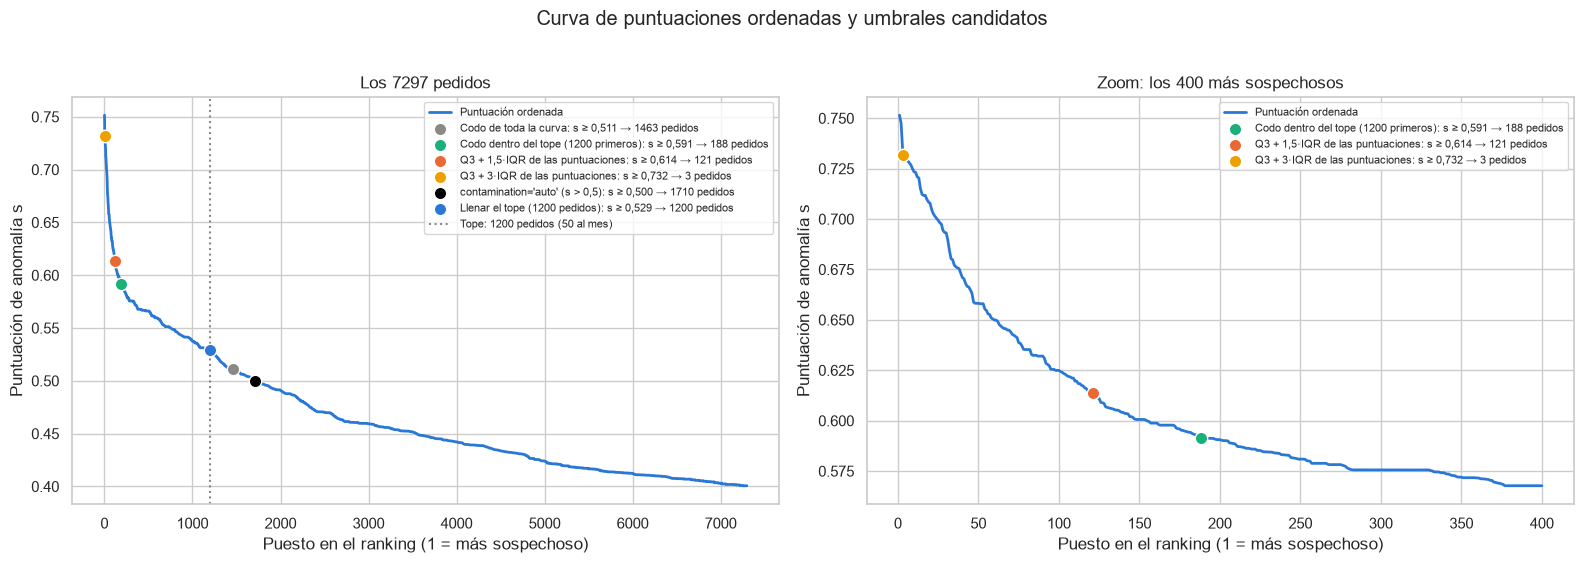

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
colores = [GRIS, VERDE_AGUA, NARANJA, AMARILLO, "black", AZUL]
for ax, hasta in zip(ejes, [len(s_ordenadas), 400]):
    puestos = np.arange(1, hasta + 1)
    ax.plot(puestos, s_ordenadas[:hasta], color=AZUL, linewidth=2, label="Puntuación ordenada")
    for (nombre, fila), color in zip(comparacion.iterrows(), colores):
        n_marcados_criterio = int(fila["pedidos con s ≥ umbral"])
        if n_marcados_criterio <= hasta:
            ax.scatter(max(n_marcados_criterio, 1), fila["umbral (s)"], color=color, s=80, zorder=3, edgecolor="white",
                       label=f"{nombre}: s ≥ {num(fila['umbral (s)'], 3)} → {n_marcados_criterio} pedidos")
    if TOPE_TOTAL <= hasta:
        ax.axvline(TOPE_TOTAL, color=GRIS, linestyle=":", linewidth=1.5, label=f"Tope: {TOPE_TOTAL} pedidos (50 al mes)")
    ax.set_xlabel("Puesto en el ranking (1 = más sospechoso)")
    ax.set_ylabel("Puntuación de anomalía s")
    ax.legend(fontsize=8, loc="upper right")
ejes[0].set_title(f"Los {len(s_ordenadas)} pedidos")
ejes[1].set_title("Zoom: los 400 más sospechosos")
fig.suptitle("Curva de puntuaciones ordenadas y umbrales candidatos", y=1.02)
fig.tight_layout()
guardar(fig, "umbral")
plt.show()

**Decisión:** se elige **Q3 + 1,5·IQR de las puntuaciones: s ≥ 0,614 → 121 pedidos (1,66 %)**, con el
tope de 50 al mes.

- **Los criterios que llenan el tope no sirven.** El codo de toda la curva (s ≥ 0,511, 1.463 pedidos),
  `contamination="auto"` (1.710) y "llenar el tope" (1.200) agotan la capacidad: llegan al tope de 50
  en 18, 22 y 12 de los 24 meses. Son los criterios que convierten la capacidad en un objetivo. El codo de toda la curva lo marca la forma de los miles de pedidos
  normales (la parte plana), no la de los raros.
- **Q3 + 3·IQR es demasiado estricto:** marca 3 pedidos (s ≥ 0,732) y deja fuera al 4.º y al 5.º, que
  puntúan 0,732 y 0,731, prácticamente igual. El corte separa pedidos casi idénticos.
- **Q3 + 1,5·IQR y el codo dentro del tope coinciden en el orden de magnitud** (121 y 188 pedidos, s ≥
  0,614 y ≥ 0,591). En el zoom se ve que a partir de ahí la curva baja despacio: los pedidos se parecen
  cada vez más entre sí.
- **Entre esos dos se elige Q3 + 1,5·IQR:** es la regla de Tukey de la sección 1, pero aplicada a una
  puntuación que ya combina las 7 variables, y no depende de ninguna elección arbitraria. El codo, en
  cambio, depende de dónde se corte la curva (con toda la curva sale 1.463; con los 1.200 primeros, 188).
  En la sección 6 se ve además que el criterio es estable con otras semillas.

In [13]:
UMBRAL = criterios["Q3 + 1,5·IQR de las puntuaciones"]
CRITERIO_UMBRAL = f"Q3 + 1,5·IQR de las puntuaciones, con un tope de {CAPACIDAD_MENSUAL} pedidos al mes"
pedidos["marcado"] = aplicar_umbral(pedidos, pedidos["puntuacion"], UMBRAL)
marcados_mes = pedidos.groupby("mes")["marcado"].sum()
print(f"Umbral elegido: s ≥ {num(UMBRAL, 4)} ({CRITERIO_UMBRAL})")
print(f"Pedidos marcados: {pedidos['marcado'].sum()} ({pct(pedidos['marcado'].mean(), 2)})")
print(f"Marcados al mes: media {num(marcados_mes.mean(), 1)}, mínimo {marcados_mes.min()}, "
      f"máximo {marcados_mes.max()} ({marcados_mes.idxmax()})")
print(f"Revisiones libres: {num(100 * (1 - marcados_mes.sum() / TOPE_TOTAL), 1)} % de la capacidad")
print(f"Coinciden con IQR: {(pedidos['marcado'] & marcado_iqr).sum()} de {pedidos['marcado'].sum()}")

Umbral elegido: s ≥ 0,6139 (Q3 + 1,5·IQR de las puntuaciones, con un tope de 50 pedidos al mes)
Pedidos marcados: 121 (1,66 %)
Marcados al mes: media 5,0, mínimo 1, máximo 10 (2024-12)
Revisiones libres: 89,9 % de la capacidad
Coinciden con IQR: 114 de 121


**Lectura:** se marcan **121 pedidos (1,66 %)**, 5,0 al mes de media, entre 1 y 10 (el máximo en
2024-12). **El tope de 50 no se alcanza ningún mes** y queda libre el 89,9 % de la capacidad: si sobra
tiempo, el equipo puede seguir bajando por el `ranking`. IQR también marca 114 de los 121, pero en total
marca 1.298.

## 4. Explicar cada alerta

Isolation Forest da una puntuación, pero no dice **por qué**. Para que alguien de negocio entienda
cada alerta, se buscan las variables más extremas del pedido:

1. Se trabaja con las variables ya transformadas (log), como las ve el modelo.
2. Para cada variable, **desviación robusta** = (valor − mediana) / escala, con
   escala = 1,4826 · MAD (MAD = mediana de |valor − mediana|). Es como una puntuación z, pero con la
   mediana en lugar de la media: los pedidos raros no deforman la referencia. El 1,4826 hace que, con
   datos normales, la escala coincida con la desviación típica.
3. Si la MAD es 0 (más de la mitad de los pedidos tiene el mismo valor, como 1 línea o precio de
   catálogo), se usa 1,2533 · la desviación media absoluta respecto a la mediana: es la versión
   habitual de la "puntuación z modificada" para ese caso.
4. **Motivo principal** = las **2 o 3 variables con mayor desviación robusta** (en valor absoluto),
   escritas en palabras y de más a menos extrema. Siempre se muestran 2; la 3.ª solo si también es
   extrema (desviación de 2 o más). Así se entienden las alertas por **combinación**: un pedido puede
   no ser extremo en nada por separado y sí en el conjunto.
5. Si "unidades totales" y "unidades en una línea" valen lo mismo (todas las unidades están en una
   línea), se muestra solo una: dirían lo mismo dos veces. Igual con los dos ratios de precio (máximo
   y mínimo), que valen lo mismo en un pedido de una sola línea. En ambos casos entra la siguiente
   variable más extrema si hace falta.

In [14]:
transformado = pd.DataFrame(pipeline.named_steps["log"].transform(pedidos[VARIABLES]),
                            columns=pipeline.named_steps["log"].get_feature_names_out(),
                            index=pedidos.index)
transformado.columns = [col.split("__")[1] for col in transformado.columns]
transformado = transformado[VARIABLES]

mediana_t = transformado.median()
mad = (transformado - mediana_t).abs().median()
desv_media = (transformado - mediana_t).abs().mean()
escala_t = (1.4826 * mad).where(mad > 0, 1.2533 * desv_media)
desviacion = (transformado - mediana_t) / escala_t

referencia_motivo = pd.DataFrame({"mediana (log)": mediana_t, "MAD": mad, "escala usada": escala_t,
                                  "mediana original": pedidos[VARIABLES].median()})
referencia_motivo.round(4)

,mediana (log),MAD,escala usada,mediana original
importe_total,4.4415,0.6683,0.9908,83.9000
n_lineas,0.6931,0.0000,0.2771,1.0000
unidades_totales,1.0986,0.4055,0.6011,2.0000
max_cantidad_linea,1.0986,0.4055,0.6011,2.0000
ratio_precio_max,0.0000,0.0000,0.0056,1.0000
ratio_precio_min,0.0000,0.0000,0.0072,1.0000
importe_por_unidad,3.7056,0.3923,0.5816,39.6733


In [15]:
MEDIANAS = pedidos[VARIABLES].median()
DESVIACION_EXTREMA = 2  # la 3.ª variable solo se muestra si su desviación robusta es de 2 o más
UNIDADES = {"unidades_totales", "max_cantidad_linea"}
RATIOS = {"ratio_precio_max", "ratio_precio_min"}


def describir_variable(variable, valor, sentido):
    """Texto para negocio: qué variable es rara, en qué sentido y cuánto vale frente a lo normal."""
    if variable.startswith("ratio"):
        lado = "por encima" if valor > 1 else "por debajo"
        return f"Precio {lado} del catálogo (×{num(valor, 2)})"
    alto_bajo = "alto" if sentido > 0 else "bajo"
    textos = {
        "importe_total": f"Importe {alto_bajo}: {euros(valor)} (mediana {euros(MEDIANAS[variable])})",
        "n_lineas": f"{'Muchas' if sentido > 0 else 'Pocas'} líneas: {valor:.0f} (mediana {MEDIANAS[variable]:.0f})",
        "unidades_totales": f"{'Muchas' if sentido > 0 else 'Pocas'} unidades: {valor:.0f} (mediana {MEDIANAS[variable]:.0f})",
        "max_cantidad_linea": f"{valor:.0f} unidades en una línea (mediana {MEDIANAS[variable]:.0f})",
        "importe_por_unidad": f"Importe por unidad {alto_bajo}: {euros(valor)} (mediana {euros(MEDIANAS[variable])})",
    }
    return textos[variable]


def variables_motivo(fila_desviacion, fila_pedido):
    """Las 2-3 variables más extremas del pedido, de más a menos extrema."""
    orden = fila_desviacion.abs().sort_values(ascending=False, kind="stable").index
    elegidas = []
    for v in orden:
        # Unidades totales y unidades en una línea con el mismo valor: solo se muestra una
        if v in UNIDADES and any(e in UNIDADES for e in elegidas) \
                and fila_pedido["unidades_totales"] == fila_pedido["max_cantidad_linea"]:
            continue
        # Lo mismo con los dos ratios de precio: en un pedido de una sola línea (o con todas las
        # líneas igual de caras) valen lo mismo y darían dos veces la misma frase. Se muestra uno
        # y, si hace falta, entra la siguiente variable más extrema.
        if v in RATIOS and any(e in RATIOS for e in elegidas) \
                and fila_pedido["ratio_precio_max"] == fila_pedido["ratio_precio_min"]:
            continue
        if len(elegidas) >= 2 and abs(fila_desviacion[v]) < DESVIACION_EXTREMA:
            break
        elegidas.append(v)
        if len(elegidas) == 3:
            break
    return elegidas


lista_motivos = [variables_motivo(desviacion.loc[i], pedidos.loc[i]) for i in pedidos.index]
pedidos["variable_motivo"] = [vs[0] for vs in lista_motivos]  # la más extrema
pedidos["desviacion_motivo"] = [desviacion.at[i, vs[0]] for i, vs in zip(pedidos.index, lista_motivos)]
pedidos["n_variables_motivo"] = [len(vs) for vs in lista_motivos]
pedidos["motivo_principal"] = [
    " · ".join(describir_variable(v, pedidos.at[i, v], desviacion.at[i, v]) for v in vs)
    for i, vs in zip(pedidos.index, lista_motivos)
]

# Ranking: 1 = el más sospechoso. Con empates, gana el id_pedido más bajo (orden estable)
pedidos = pedidos.sort_values(["puntuacion", "id_pedido"], ascending=[False, True], kind="stable")
pedidos["ranking"] = np.arange(1, len(pedidos) + 1)
pedidos = pedidos.sort_values("id_pedido").reset_index(drop=True)
desviacion = desviacion.loc[pedidos.index]

top15 = pedidos.nsmallest(15, "ranking")
with pd.option_context("display.max_colwidth", None):
    display(top15[["ranking", "id_pedido", "estado", "puntuacion", "motivo_principal"]].round({"puntuacion": 3}))
top15[["ranking", "id_pedido"] + VARIABLES].round(
    {"importe_total": 2, "ratio_precio_max": 2, "ratio_precio_min": 2, "importe_por_unidad": 2})

,ranking,id_pedido,estado,puntuacion,motivo_principal
322,1,348,completado,0.752,Importe alto: 11.730 € (mediana 84 €) · Muchas unidades: 54 (mediana 2) · Importe por unidad alto: 217 € (mediana 40 €)
5994,2,6477,completado,0.748,Importe alto: 10.390 € (mediana 84 €) · Muchas unidades: 48 (mediana 2) · Importe por unidad alto: 216 € (mediana 40 €)
2599,3,2791,completado,0.733,Muchas unidades: 59 (mediana 2) · Importe alto: 756 € (mediana 84 €)
4398,4,4745,completado,0.732,Muchas unidades: 58 (mediana 2) · Importe por unidad bajo: 9 € (mediana 40 €)
3298,5,3547,completado,0.731,Muchas unidades: 50 (mediana 2) · Importe alto: 3.435 € (mediana 84 €)
7085,6,7664,cancelado,0.729,Muchas unidades: 58 (mediana 2) · Importe alto: 922 € (mediana 84 €)
2035,7,2183,devuelto,0.728,Muchas unidades: 51 (mediana 2) · Importe alto: 3.020 € (mediana 84 €)
5450,8,5886,completado,0.727,Muchas unidades: 57 (mediana 2) · Importe alto: 2.898 € (mediana 84 €)
3777,9,4071,completado,0.725,Muchas unidades: 51 (mediana 2) · Importe alto: 2.289 € (mediana 84 €)
7223,10,7813,completado,0.723,Muchas unidades: 46 (mediana 2) · 43 unidades en una línea (mediana 2) · Importe alto: 3.147 € (mediana 84 €)


,ranking,id_pedido,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
322,1,348,11730.42,1,54,54,1.0,1.0,217.23
5994,2,6477,10389.60,1,48,48,1.0,1.0,216.45
2599,3,2791,755.79,1,59,59,1.0,1.0,12.81
4398,4,4745,530.12,1,58,58,1.0,1.0,9.14
3298,5,3547,3435.50,1,50,50,1.0,1.0,68.71
7085,6,7664,921.62,1,58,58,1.0,1.0,15.89
2035,7,2183,3019.71,1,51,51,1.0,1.0,59.21
5450,8,5886,2897.88,1,57,57,1.0,1.0,50.84
3777,9,4071,2288.88,1,51,51,1.0,1.0,44.88
7223,10,7813,3147.04,3,46,43,1.0,1.0,68.41


In [16]:
# Variable más extrema y nº de variables del motivo en los pedidos marcados
marcados = pedidos[pedidos["marcado"]]
print("Variable más extrema de los pedidos marcados:")
print(marcados["variable_motivo"].map(ETIQUETAS).value_counts().to_string())
print("\nNº de variables en el motivo:")
print(marcados["n_variables_motivo"].value_counts().sort_index().to_string())

Variable más extrema de los pedidos marcados:
variable_motivo
Nº de líneas (productos distintos)    49
Importe por unidad (€)                31
Unidades totales                      23
Precio cobrado / catálogo (máx.)       9
Importe del pedido (€)                 7
Precio cobrado / catálogo (mín.)       2

Nº de variables en el motivo:
n_variables_motivo
2    67
3    54


**Lectura:** cada alerta lleva ahora **2 o 3 variables**: 67 de los 121 marcados tienen 2 y 54 tienen 3.
Algunos ejemplos:

- Puesto 12: "Muchas líneas: 10 · Muchas unidades: 24 · Importe alto: 1.813 €". Es raro por la suma de
  las tres cosas.
- Puesto 4: "Muchas unidades: 58 · Importe por unidad bajo: 9 €". Muchas unidades de un producto barato.
- Puesto 1: "Importe alto: 11.730 € · Muchas unidades: 54 · Importe por unidad alto: 217 €". Muchas
  unidades del producto más caro.

Entre los marcados, la variable más extrema es el nº de líneas en 49, el importe por unidad en 31, las
unidades en 23, el precio por encima del catálogo en 9, el importe en 7 y el precio por debajo del
catálogo en 2. Alguien de negocio no ve "puntuación 0,73": ve "**58 unidades de un producto de 9 €
cuando lo normal son 2 unidades de 40 €**".

## 5. Gráficos (sin la verdad)

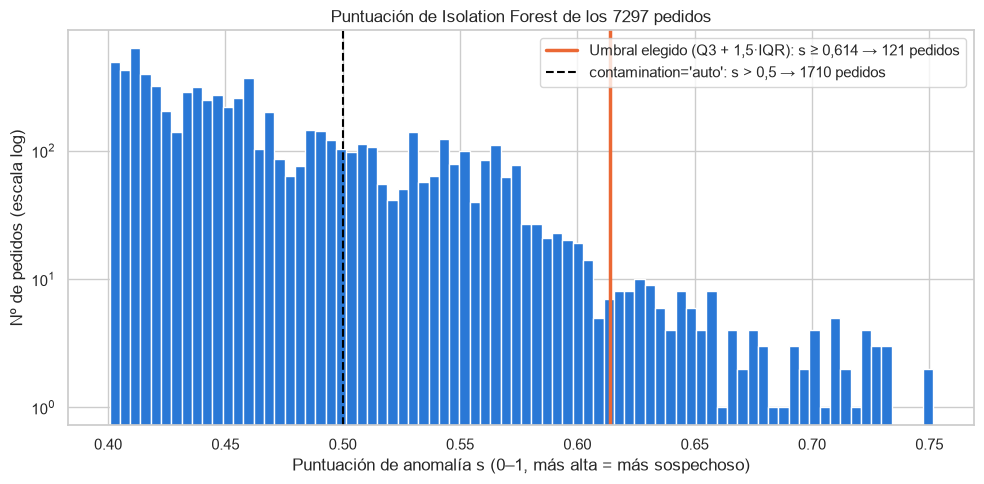

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pedidos["puntuacion"], bins=80, color=AZUL, edgecolor="white")
ax.axvline(UMBRAL, color=NARANJA, linewidth=2.5,
           label=f"Umbral elegido (Q3 + 1,5·IQR): s ≥ {num(UMBRAL, 3)} → {pedidos['marcado'].sum()} pedidos")
ax.axvline(UMBRAL_AUTO, color="black", linestyle="--", linewidth=1.5,
           label=f"contamination='auto': s > 0,5 → {(pedidos['puntuacion'] > UMBRAL_AUTO).sum()} pedidos")
ax.set_yscale("log")
ax.set_xlabel("Puntuación de anomalía s (0–1, más alta = más sospechoso)")
ax.set_ylabel("Nº de pedidos (escala log)")
ax.set_title(f"Puntuación de Isolation Forest de los {len(pedidos)} pedidos")
ax.legend()
fig.tight_layout()
guardar(fig, "puntuaciones")
plt.show()

**Lectura:** la mayoría de los pedidos puntúa entre 0,40 y 0,50 y la cola baja de forma gradual: **no
hay un hueco** que separe a los normales de los raros. Solo el 1 % pasa de 0,641. El umbral elegido
(0,614) queda en la cola, lejos del 0,5 de `contamination="auto"`, que se mete en la parte densa del
histograma y marca 1.710 pedidos.

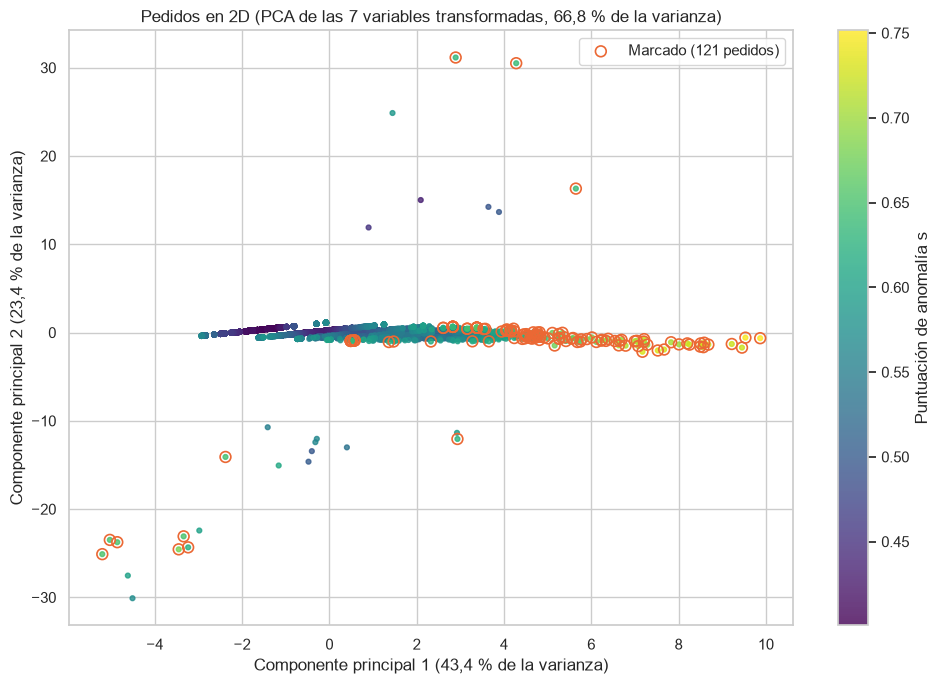

,CP1,CP2
importe_total,0.53,0.08
n_lineas,0.42,-0.09
unidades_totales,0.54,-0.14
max_cantidad_linea,0.44,-0.12
ratio_precio_max,0.24,0.26
ratio_precio_min,0.06,0.66
importe_por_unidad,0.04,0.67


In [18]:
X_escalado = pipeline[:-1].transform(pedidos[VARIABLES])
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_escalado)
coords = pca.transform(X_escalado)
varianza = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 7))
orden = np.argsort(pedidos["puntuacion"].to_numpy())  # los más sospechosos se dibujan encima
puntos_pca = ax.scatter(coords[orden, 0], coords[orden, 1], c=pedidos["puntuacion"].to_numpy()[orden],
                        cmap="viridis", s=12, alpha=0.8)
marc = pedidos["marcado"].to_numpy()
ax.scatter(coords[marc, 0], coords[marc, 1], facecolors="none", edgecolors=NARANJA, s=60, linewidths=1.2,
           label=f"Marcado ({marc.sum()} pedidos)")
fig.colorbar(puntos_pca, ax=ax, label="Puntuación de anomalía s")
ax.set_xlabel(f"Componente principal 1 ({pct(varianza[0])} de la varianza)")
ax.set_ylabel(f"Componente principal 2 ({pct(varianza[1])} de la varianza)")
ax.set_title(f"Pedidos en 2D (PCA de las 7 variables transformadas, {pct(varianza.sum())} de la varianza)")
ax.legend(loc="upper right")
fig.tight_layout()
guardar(fig, "pca")
plt.show()

cargas = pd.DataFrame(pca.components_.T, index=VARIABLES, columns=["CP1", "CP2"]).round(2)
cargas

**Lectura:** el PCA resume las 7 variables en 2 con el 66,8 % de la varianza. La **componente 1
(43,4 %)** es el **tamaño del pedido**: pesan importe, unidades, líneas y máx. unidades por línea
(cargas de 0,42 a 0,54). La **componente 2 (23,4 %)** es el **precio**: pesan el ratio mínimo (0,66) y el
importe por unidad (0,67). Los 121 marcados (círculos naranjas) son los extremos de la nube: los pedidos
más grandes, a la derecha, y varios de los puntos sueltos de arriba y de abajo, que son precios lejos del
catálogo. **Otros puntos sueltos tienen puntuación media o baja y no están marcados**, aunque en 2D se
ven claramente aislados.

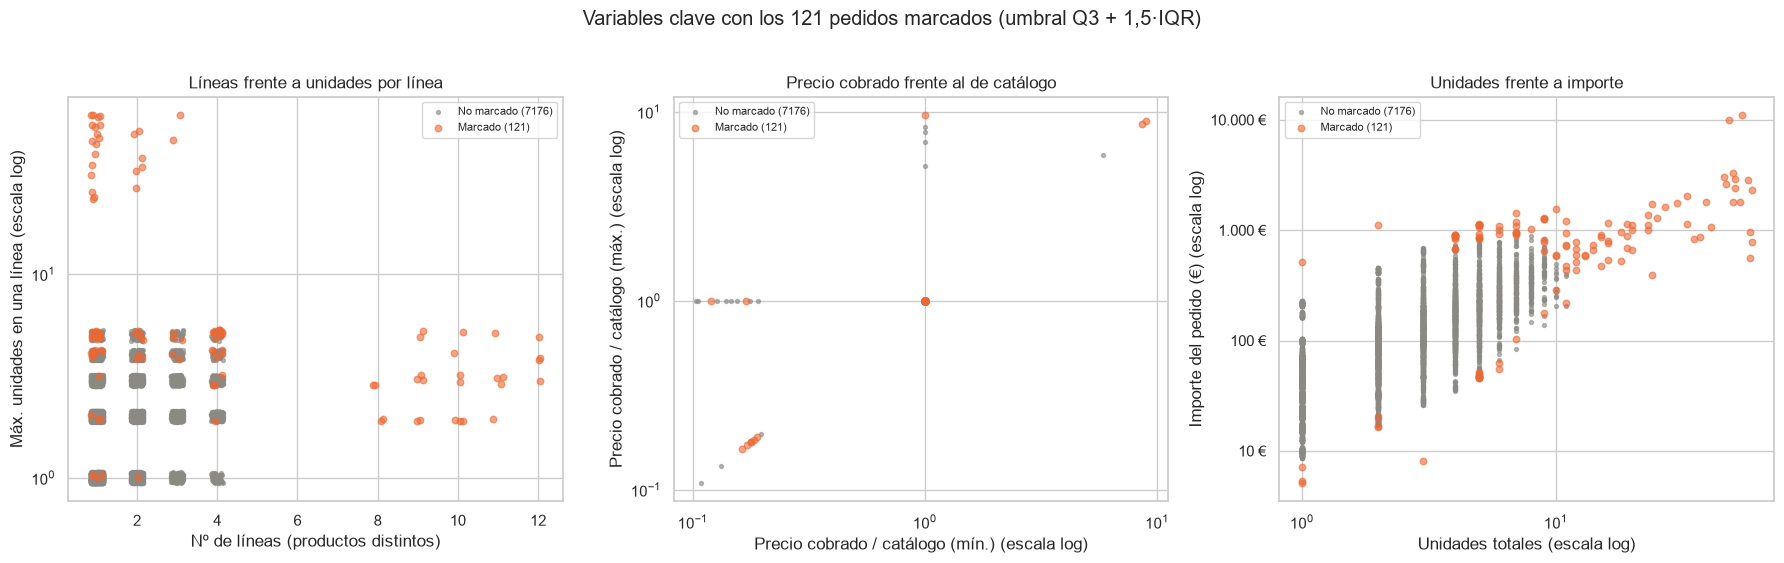

Pedidos con 8 o más líneas: 27, marcados: 27
Pedidos con 20 o más unidades en una línea: 25, marcados: 25
Pedidos con precio por encima del catálogo: 8, marcados: 3
Pedidos con precio por debajo del catálogo: 19, marcados: 8
Marcados sin ninguna de esas cuatro características: 58


In [19]:
rng = np.random.default_rng(SEMILLA)  # pequeño "jitter" para que no se tapen los valores enteros repetidos


def jitter(serie, ancho=0.15):
    return serie + rng.uniform(-ancho, ancho, size=len(serie))


normales = pedidos[~pedidos["marcado"]]
sospechosos = pedidos[pedidos["marcado"]]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
paneles = [
    ("n_lineas", "max_cantidad_linea", False, True),
    ("ratio_precio_min", "ratio_precio_max", True, True),
    ("unidades_totales", "importe_total", True, True),
]
for ax, (vx, vy, logx, logy) in zip(ejes, paneles):
    for datos, color, nombre, tam in [(normales, GRIS, f"No marcado ({len(normales)})", 8),
                                      (sospechosos, NARANJA, f"Marcado ({len(sospechosos)})", 22)]:
        x = datos[vx] if logx else jitter(datos[vx])
        y = datos[vy] if vx.startswith("ratio") else datos[vy] * np.exp(rng.uniform(-0.06, 0.06, size=len(datos)))
        ax.scatter(x, y, s=tam, color=color, alpha=0.6, label=nombre)
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(ETIQUETAS[vx] + (" (escala log)" if logx else ""))
    ax.set_ylabel(ETIQUETAS[vy] + (" (escala log)" if logy else ""))
    ax.legend(fontsize=8)
ejes[0].set_title("Líneas frente a unidades por línea")
ejes[1].set_title("Precio cobrado frente al de catálogo")
ejes[2].set_title("Unidades frente a importe")
ejes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _p: euros(v)))
fig.suptitle(f"Variables clave con los {len(sospechosos)} pedidos marcados (umbral Q3 + 1,5·IQR)", y=1.02)
fig.tight_layout()
guardar(fig, "dispersion")
plt.show()

print(f"Pedidos con 8 o más líneas: {(pedidos['n_lineas'] >= 8).sum()}, marcados: "
      f"{(pedidos['marcado'] & (pedidos['n_lineas'] >= 8)).sum()}")
print(f"Pedidos con 20 o más unidades en una línea: {(pedidos['max_cantidad_linea'] >= 20).sum()}, marcados: "
      f"{(pedidos['marcado'] & (pedidos['max_cantidad_linea'] >= 20)).sum()}")
por_encima = pedidos["ratio_precio_max"] > 1.001
por_debajo = pedidos["ratio_precio_min"] < 0.999
print(f"Pedidos con precio por encima del catálogo: {por_encima.sum()}, marcados: {(pedidos['marcado'] & por_encima).sum()}")
print(f"Pedidos con precio por debajo del catálogo: {por_debajo.sum()}, marcados: {(pedidos['marcado'] & por_debajo).sum()}")
otros = pedidos["marcado"] & ~por_encima & ~por_debajo & (pedidos["n_lineas"] < 8) & (pedidos["max_cantidad_linea"] < 20)
print(f"Marcados sin ninguna de esas cuatro características: {otros.sum()}")

**Lectura:** los 27 pedidos con 8 o más líneas y los 25 con 20 o más unidades en una línea están
todos marcados (izquierda). En precios (centro), se marcan **8 de los 19 pedidos con precio por debajo
del catálogo y 3 de los 8 con precio por encima**. Los otros 58 marcados no tienen ninguna de esas
cuatro características: son pedidos raros por la **combinación** (a la derecha, los grandes y caros: muchas
unidades e importe alto a la vez).

## 6. Estabilidad

Isolation Forest es aleatorio (qué pedidos usa cada árbol, qué variable y qué valor corta). Si con
otra semilla marcara pedidos muy distintos, las alertas dependerían de la suerte. Se repite el modelo
con 5 semillas distintas, marcando el **mismo número de pedidos** que el modelo final (sus N más
sospechosos), y se mide:

- **Jaccard** = |A ∩ B| / |A ∪ B| entre los pedidos marcados: 1 = los mismos, 0 = ninguno en común.
- El solape del **top 50** (los que se revisarían primero).
- La **correlación de Spearman** entre las puntuaciones (si ordenan igual los pedidos).
- Además, cuántos pedidos marcaría cada semilla con **su propio** umbral Q3 + 1,5·IQR: así se ve si el
  criterio del umbral también es estable.

In [20]:
SEMILLAS_ESTABILIDAD = [1, 2, 3, 4, 5]
n_marcados = int(pedidos["marcado"].sum())


def conjunto_marcados(puntuacion, n):
    """Los n pedidos con más puntuación (con empates, el id más bajo, como en el ranking)."""
    orden = pd.DataFrame({"s": puntuacion, "id": pedidos["id_pedido"]}).sort_values(
        ["s", "id"], ascending=[False, True], kind="stable")
    return set(orden["id"].head(n))


def jaccard(a, b):
    return len(a & b) / len(a | b)


puntuaciones = {SEMILLA: pedidos["puntuacion"].to_numpy()}
for semilla in SEMILLAS_ESTABILIDAD:
    modelo = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO, semilla=semilla).fit(pedidos[VARIABLES])
    puntuaciones[semilla] = puntuar(modelo, pedidos[VARIABLES])

base_marcados = conjunto_marcados(puntuaciones[SEMILLA], n_marcados)
base_top50 = conjunto_marcados(puntuaciones[SEMILLA], 50)
filas = []
for semilla in SEMILLAS_ESTABILIDAD:
    marcados_s = conjunto_marcados(puntuaciones[semilla], n_marcados)
    top50_s = conjunto_marcados(puntuaciones[semilla], 50)
    umbral_s = umbral_iqr(puntuaciones[semilla], 1.5)
    filas.append({
        "semilla": semilla,
        "Jaccard marcados (vs 42)": jaccard(marcados_s, base_marcados),
        "% de los marcados en común": 100 * len(marcados_s & base_marcados) / n_marcados,
        "top 50 en común": len(top50_s & base_top50),
        "Spearman puntuaciones": spearmanr(puntuaciones[semilla], puntuaciones[SEMILLA]).statistic,
        "umbral propio Q3 + 1,5·IQR": umbral_s,
        "marcados con su umbral": int(aplicar_umbral(pedidos, puntuaciones[semilla], umbral_s).sum()),
    })
estabilidad = pd.DataFrame(filas).set_index("semilla")

todas = set.intersection(*[conjunto_marcados(p, n_marcados) for p in puntuaciones.values()])
alguna = set.union(*[conjunto_marcados(p, n_marcados) for p in puntuaciones.values()])
print(f"Marcados por cada modelo: {n_marcados}")
print(f"Marcados con las 6 semillas: {len(todas)} · con alguna: {len(alguna)}")
print(f"Jaccard medio con la semilla 42: {num(estabilidad['Jaccard marcados (vs 42)'].mean(), 3)}")
estabilidad.round(3)

Marcados por cada modelo: 121
Marcados con las 6 semillas: 109 · con alguna: 137
Jaccard medio con la semilla 42: 0,897


,Jaccard marcados (vs 42),% de los marcados en común,top 50 en común,Spearman puntuaciones,"umbral propio Q3 + 1,5·IQR",marcados con su umbral
semilla,,,,,,
1,0.921,95.868,46,0.992,0.613,120
2,0.862,92.562,47,0.988,0.614,109
3,0.891,94.215,47,0.979,0.614,119
4,0.906,95.041,47,0.988,0.616,118
5,0.906,95.041,47,0.989,0.619,121


**Lectura:** el modelo es **estable**. Con otras semillas, entre el 92,6 % y el 95,9 % de los pedidos
marcados coinciden con los de la semilla 42 (Jaccard medio 0,897), del top 50 coinciden 46 o 47, y la
correlación de Spearman entre puntuaciones está entre 0,979 y 0,992. 109 pedidos se marcan con las 6
semillas y 137 con alguna. **El criterio del umbral también es estable**: con su propio Q3 + 1,5·IQR
(entre 0,613 y 0,619), cada semilla marca entre 109 y 121 pedidos. Para el negocio: las alertas de
arriba del ranking son fiables; las que están justo en el umbral entran o salen según el azar, pero
tienen puntuaciones casi iguales a las de los pedidos que se quedan fuera.

## 6b. Guardar el modelo y el CSV

Se guardan antes de la evaluación: el modelo y el umbral no dependen de la verdad.

In [21]:
# "datos_hasta" es el último día con pedidos (no la fecha de hoy): con los mismos datos, el archivo es
# idéntico entre ejecuciones. "referencia_motivo" permite explicar las alertas de pedidos nuevos.
# Sus claves son las mismas cadenas de VARIABLES (no las del índice de pandas): pickle guarda una
# cadena una sola vez si es el mismo objeto, y si las claves fueran copias, que pandas a veces
# comparte y a veces no, el archivo cambiaría de bytes entre ejecuciones sin cambiar de contenido.
def a_dict(serie):
    return {v: float(serie.round(10)[v]) for v in VARIABLES}


paquete = {
    "pipeline": pipeline,
    "variables": VARIABLES,
    "variables_log1p": VARIABLES_LOG1P,
    "variables_log": VARIABLES_RATIO,
    "puntuacion": "s = -pipeline.score_samples(X): entre 0 y 1, más alta = más sospechoso",
    "umbral": UMBRAL,
    "criterio_umbral": CRITERIO_UMBRAL,
    "capacidad_mensual": CAPACIDAD_MENSUAL,
    "referencia_motivo": {"mediana": a_dict(mediana_t), "escala": a_dict(escala_t),
                          "desviacion_extrema": DESVIACION_EXTREMA},
    "datos_hasta": str(pedidos["fecha_pedido"].max().date()),
}
ruta_modelo = CARPETA_MODELOS / "anomalias_iforest.joblib"
joblib.dump(paquete, ruta_modelo)
print("Modelo guardado en", ruta_modelo.relative_to(RAIZ))

# Comprobación: se carga, da las mismas puntuaciones y marcas, y puntúa pedidos "nuevos"
cargado = joblib.load(ruta_modelo)
s_cargado = -cargado["pipeline"].score_samples(pedidos[cargado["variables"]])
assert np.allclose(s_cargado, pedidos["puntuacion"])
assert (aplicar_umbral(pedidos, s_cargado, cargado["umbral"], cargado["capacidad_mensual"]) == pedidos["marcado"]).all()
ejemplo = pd.DataFrame({
    "importe_total": [60.0, 2400.0, 6.0], "n_lineas": [1, 1, 1], "unidades_totales": [2, 40, 1],
    "max_cantidad_linea": [2, 40, 1], "ratio_precio_max": [1.0, 1.0, 0.12], "ratio_precio_min": [1.0, 1.0, 0.12],
    "importe_por_unidad": [30.0, 60.0, 6.0],
}, index=["normal", "40 unidades", "precio ×0,12"])
s_ejemplo = -cargado["pipeline"].score_samples(ejemplo[cargado["variables"]])
for nombre, s in zip(ejemplo.index, s_ejemplo):
    print(f"Pedido {nombre:<12} → s = {num(s, 3)} → {'MARCADO' if s >= cargado['umbral'] else 'no marcado'}")
print("Umbral:", num(cargado["umbral"], 4), "·", cargado["criterio_umbral"])
print("datos_hasta =", cargado["datos_hasta"])

Modelo guardado en models\anomalias_iforest.joblib


Pedido normal       → s = 0,419 → no marcado
Pedido 40 unidades  → s = 0,718 → MARCADO
Pedido precio ×0,12 → s = 0,659 → MARCADO
Umbral: 0,6139 · Q3 + 1,5·IQR de las puntuaciones, con un tope de 50 pedidos al mes
datos_hasta = 2026-10-31


In [22]:
# Para el Power BI de la S10. motivo_principal solo se rellena en los pedidos marcados: en un pedido
# normal, "sus variables más raras" no son el motivo de nada y confundirían al leer el informe.
sospechosos_csv = pedidos[["id_pedido", "puntuacion", "ranking", "marcado", "motivo_principal"]].copy()
sospechosos_csv["puntuacion"] = sospechosos_csv["puntuacion"].round(6)
sospechosos_csv["marcado"] = sospechosos_csv["marcado"].astype(int)
sospechosos_csv.loc[sospechosos_csv["marcado"] == 0, "motivo_principal"] = ""
ruta_csv = RAIZ / "data" / "processed" / "pedidos_sospechosos.csv"
sospechosos_csv.to_csv(ruta_csv, index=False, encoding="utf-8")
print(f"Guardado {ruta_csv.relative_to(RAIZ)}: {len(sospechosos_csv)} pedidos, {sospechosos_csv['marcado'].sum()} marcados")
with pd.option_context("display.max_colwidth", None):
    display(sospechosos_csv.sort_values("ranking").head())

Guardado data\processed\pedidos_sospechosos.csv: 7297 pedidos, 121 marcados


,id_pedido,puntuacion,ranking,marcado,motivo_principal
322,348,0.751503,1,1,Importe alto: 11.730 € (mediana 84 €) · Muchas unidades: 54 (mediana 2) · Importe por unidad alto: 217 € (mediana 40 €)
5994,6477,0.747525,2,1,Importe alto: 10.390 € (mediana 84 €) · Muchas unidades: 48 (mediana 2) · Importe por unidad alto: 216 € (mediana 40 €)
2599,2791,0.733294,3,1,Muchas unidades: 59 (mediana 2) · Importe alto: 756 € (mediana 84 €)
4398,4745,0.731671,4,1,Muchas unidades: 58 (mediana 2) · Importe por unidad bajo: 9 € (mediana 40 €)
3298,3547,0.731425,5,1,Muchas unidades: 50 (mediana 2) · Importe alto: 3.435 € (mediana 84 €)


---

## 7. EVALUACIÓN con la verdad

> **A partir de aquí se usa `_verdad_anomalias.csv`.** Nada de lo anterior (variables, transformación,
> hiperparámetros, umbral) se ha decidido con ella. En una empresa real esta sección no existe.

Métricas (anomalía = clase positiva):

- **Precision** = de los pedidos marcados, cuántos son anomalías de verdad.
- **Recall** = de las anomalías de verdad, cuántas se marcan.
- **F1** = media armónica de las dos: solo es alta si las dos lo son.
- **ROC-AUC** = probabilidad de que una anomalía al azar tenga más puntuación que un pedido normal al
  azar (0,5 = azar, 1 = perfecto). No depende del umbral.
- **Average precision (PR-AUC)** = área bajo la curva precision–recall. Con clases muy desequilibradas
  es más exigente que la ROC-AUC: el azar da la proporción de anomalías, no 0,5.

**Comparación justa:** IQR marca un número de pedidos y el umbral elegido otro muy distinto, así que
comparar sus precision y recall mezcla "qué método es mejor" con "cuántas alertas da cada uno". Por eso
también se compara IQR con **los N pedidos de más puntuación de Isolation Forest, con N = los que marca
IQR**: mismo número de alertas, distinto método.

In [23]:
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,  # noqa: E402
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score)

verdad = pd.read_csv(RAIZ / "data" / "raw" / "_verdad_anomalias.csv")
assert verdad["id_pedido"].isin(pedidos["id_pedido"]).all()
evaluacion = pedidos.merge(verdad, on="id_pedido", how="left")
evaluacion["es_anomalia"] = evaluacion["tipo_anomalia"].notna()
# El generador solo dice "precio_anomalo": se separa en alto o bajo con el ratio del propio pedido
precio = evaluacion["tipo_anomalia"] == "precio_anomalo"
evaluacion.loc[precio, "tipo_anomalia"] = np.where(evaluacion.loc[precio, "ratio_precio_max"] > 1.001,
                                                   "precio_alto", "precio_bajo")
evaluacion["marcado_iqr"] = marcado_iqr.to_numpy()
N_IQR = int(evaluacion["marcado_iqr"].sum())
evaluacion["top_n_iqr"] = evaluacion["ranking"] <= N_IQR
evaluacion["top50"] = evaluacion["ranking"] <= 50
y = evaluacion["es_anomalia"]

prevalencia = y.mean()
print(f"Anomalías reales: {y.sum()} de {len(y)} ({pct(prevalencia, 2)})")
print(evaluacion.loc[y, "tipo_anomalia"].value_counts().to_string())
print(f"\nAccuracy de un 'modelo' que no marca NADA: {pct(1 - prevalencia, 2)} (y no encuentra ni una anomalía)")

Anomalías reales: 79 de 7297 (1,08 %)
tipo_anomalia
muchas_lineas      27
cantidad_enorme    25
precio_bajo        19
precio_alto         8

Accuracy de un 'modelo' que no marca NADA: 98,92 % (y no encuentra ni una anomalía)


In [24]:
def metricas(nombre, marcado):
    return {
        "método": nombre,
        "marcados": int(marcado.sum()),
        "anomalías encontradas": int((marcado & y).sum()),
        "precision": precision_score(y, marcado),
        "recall": recall_score(y, marcado),
        "F1": f1_score(y, marcado),
        "accuracy": (marcado == y).mean(),
    }


n_elegido = int(evaluacion["marcado"].sum())
tabla_metricas = pd.DataFrame([
    metricas("IQR (una variable cada vez)", evaluacion["marcado_iqr"]),
    metricas(f"Isolation Forest, top {N_IQR} (mismo nº que IQR)", evaluacion["top_n_iqr"]),
    metricas("Isolation Forest, umbral elegido (Q3 + 1,5·IQR)", evaluacion["marcado"]),
]).set_index("método")
roc_auc = roc_auc_score(y, evaluacion["puntuacion"])
ap = average_precision_score(y, evaluacion["puntuacion"])
print(f"Isolation Forest con la puntuación continua: ROC-AUC = {num(roc_auc, 3)} · "
      f"average precision (PR-AUC) = {num(ap, 3)} (azar = {num(prevalencia, 3)})")
print(f"Precision máxima posible marcando {N_IQR} pedidos: {y.sum()} / {N_IQR} = {pct(y.sum() / N_IQR)}")
tabla_metricas.round(3)

Isolation Forest con la puntuación continua: ROC-AUC = 0,968 · average precision (PR-AUC) = 0,762 (azar = 0,011)
Precision máxima posible marcando 1298 pedidos: 79 / 1298 = 6,1 %


,marcados,anomalías encontradas,precision,recall,F1,accuracy
método,,,,,,
IQR (una variable cada vez),1298,62,0.048,0.785,0.090,0.828
"Isolation Forest, top 1298 (mismo nº que IQR)",1298,73,0.056,0.924,0.106,0.831
"Isolation Forest, umbral elegido (Q3 + 1,5·IQR)",121,63,0.521,0.797,0.630,0.990


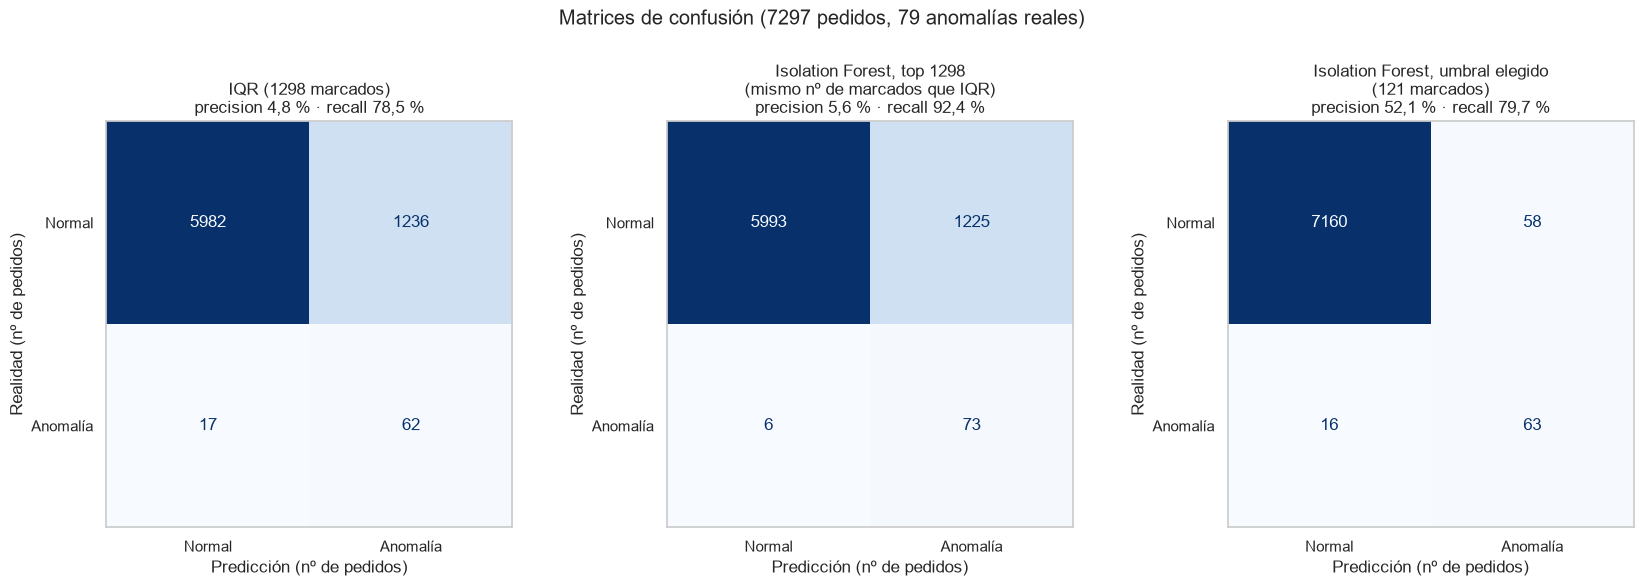

In [25]:
paneles_cm = [(f"IQR ({N_IQR} marcados)", "marcado_iqr"),
              (f"Isolation Forest, top {N_IQR}\n(mismo nº de marcados que IQR)", "top_n_iqr"),
              (f"Isolation Forest, umbral elegido\n({n_elegido} marcados)", "marcado")]
fig, ejes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (nombre, columna) in zip(ejes, paneles_cm):
    matriz = confusion_matrix(y, evaluacion[columna])
    ConfusionMatrixDisplay(matriz, display_labels=["Normal", "Anomalía"]).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                                values_format="d")
    ax.set_title(f"{nombre}\nprecision {pct(precision_score(y, evaluacion[columna]))} · "
                 f"recall {pct(recall_score(y, evaluacion[columna]))}")
    ax.set_xlabel("Predicción (nº de pedidos)")
    ax.set_ylabel("Realidad (nº de pedidos)")
    ax.grid(False)
fig.suptitle(f"Matrices de confusión ({len(y)} pedidos, {y.sum()} anomalías reales)", y=1.03)
fig.tight_layout()
guardar(fig, "matrices_confusion")
plt.show()

**Lectura:** 

- **Comparación justa (mismo número de alertas, 1.298):** Isolation Forest encuentra **73 anomalías y
  IQR 62**. Recall: 92,4 % frente a 78,5 %. Precision: 5,6 % frente a 4,8 %. F1: 0,106 frente a 0,090.
  Con el mismo trabajo de revisión, el modelo encuentra 11 anomalías más. La precision es baja en los
  dos porque 1.298 alertas son muchas más que 79 anomalías: el máximo posible es 6,1 %.
- **Con el umbral elegido (121 alertas):** encuentra **63 de 79**. **Precision 52,1 %** (una de cada dos
  alertas es un problema real), recall 79,7 % y **F1 0,630**. Con 10 veces menos alertas que IQR,
  encuentra casi las mismas anomalías (63 frente a 62).
- **El accuracy no sirve:** no marcar nada da un 98,92 % y no encuentra ni una anomalía. El umbral
  elegido da un 99,0 %, casi lo mismo, aunque encuentra 63. Con un 1,08 % de anomalías, el accuracy
  premia ignorarlas.

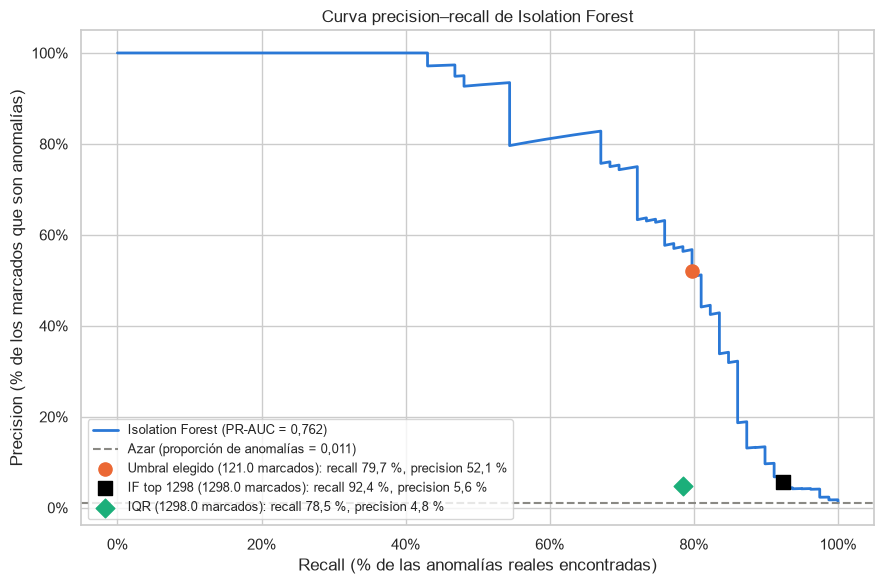

In [26]:
precision_c, recall_c, _ = precision_recall_curve(y, evaluacion["puntuacion"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(recall_c, precision_c, color=AZUL, linewidth=2, label=f"Isolation Forest (PR-AUC = {num(ap, 3)})")
ax.axhline(prevalencia, color=GRIS, linestyle="--", label=f"Azar (proporción de anomalías = {num(prevalencia, 3)})")
puntos_pr = [
    ("Umbral elegido", tabla_metricas.iloc[2], NARANJA, "o"),
    (f"IF top {N_IQR}", tabla_metricas.iloc[1], "black", "s"),
    ("IQR", tabla_metricas.iloc[0], VERDE_AGUA, "D"),
]
for nombre, fila, color, marcador in puntos_pr:
    ax.scatter(fila["recall"], fila["precision"], color=color, marker=marcador, s=90, zorder=3,
               label=f"{nombre} ({fila['marcados']} marcados): recall {pct(fila['recall'])}, precision {pct(fila['precision'])}")
ax.set_xlabel("Recall (% de las anomalías reales encontradas)")
ax.set_ylabel("Precision (% de los marcados que son anomalías)")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Curva precision–recall de Isolation Forest")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
guardar(fig, "precision_recall")
plt.show()

**Lectura:** **ROC-AUC = 0,968** y **PR-AUC = 0,762**, frente a 0,011 del azar. Las dos no dependen del
umbral. La curva se queda en el 100 % de precision hasta el 43,0 % de recall: los 34 primeros pedidos del
ranking son todos anomalías. El umbral elegido (naranja) está en la zona útil de la curva: recall del
79,7 % con precision del 52,1 %. Con 1.298 alertas (negro), Isolation Forest llega al 92,4 % de recall,
pero con una precision del 5,6 %. IQR (verde) queda por debajo de la curva: con su número de alertas,
Isolation Forest encuentra más anomalías.

### Recall por tipo de anomalía

In [27]:
TIPOS = ["cantidad_enorme", "precio_alto", "precio_bajo", "muchas_lineas"]
anomalias = evaluacion[y]


def recall_por_tipo(columna_marcado):
    return evaluacion[y].groupby("tipo_anomalia")[columna_marcado].mean().reindex(TIPOS)


por_tipo = pd.DataFrame({
    "anomalías": anomalias["tipo_anomalia"].value_counts().reindex(TIPOS),
    "recall IQR": recall_por_tipo("marcado_iqr"),
    f"recall IForest top {N_IQR}": recall_por_tipo("top_n_iqr"),
    "recall IForest umbral elegido": recall_por_tipo("marcado"),
    "recall IForest top 50": recall_por_tipo("top50"),
    "ranking mediano": anomalias.groupby("tipo_anomalia")["ranking"].median().reindex(TIPOS),
    "ranking peor": anomalias.groupby("tipo_anomalia")["ranking"].max().reindex(TIPOS),
})
por_tipo.round(3)

,anomalías,recall IQR,recall IForest top 1298,recall IForest umbral elegido,recall IForest top 50,ranking mediano,ranking peor
tipo_anomalia,,,,,,,
cantidad_enorme,25,1.000,1.000,1.000,1.000,14.0,37
precio_alto,8,1.000,0.500,0.375,0.000,1008.5,4541
precio_bajo,19,0.105,0.895,0.421,0.053,146.0,1780
muchas_lineas,27,1.000,1.000,1.000,0.630,43.0,111


In [28]:
# Las anomalías que se le escapan al umbral elegido
escapadas = anomalias[~anomalias["marcado"]]
print(f"Anomalías no marcadas con el umbral elegido: {len(escapadas)}")
print(escapadas["tipo_anomalia"].value_counts().reindex(TIPOS, fill_value=0).to_string())
print(f"\nPuntuación de las que se escapan: de {num(escapadas['puntuacion'].min(), 3)} a "
      f"{num(escapadas['puntuacion'].max(), 3)} (umbral {num(UMBRAL, 3)})")
escapadas.groupby("tipo_anomalia")[["ranking", "puntuacion", "n_lineas", "max_cantidad_linea",
                                    "ratio_precio_max", "ratio_precio_min", "importe_por_unidad"]].median().round(3)

Anomalías no marcadas con el umbral elegido: 16
tipo_anomalia
cantidad_enorme     0
precio_alto         5
precio_bajo        11
muchas_lineas       0

Puntuación de las que se escapan: de 0,433 a 0,611 (umbral 0,614)


,ranking,puntuacion,n_lineas,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
tipo_anomalia,,,,,,,
precio_alto,1878.0,0.494,2.0,2.0,6.86,1.000,44.820
precio_bajo,527.0,0.563,2.0,2.0,1.00,0.139,23.225


In [29]:
# Cada árbol se entrena con 256 pedidos al azar (max_samples). ¿Qué parte de los árboles no ve NINGÚN
# pedido con el precio distinto del catálogo? En esos árboles el ratio vale 1 en todos los pedidos y no
# se puede cortar por él.
n_muestra = pipeline.named_steps["iforest"].max_samples_
for nombre, cuantos in [("por encima", (pedidos["ratio_precio_max"] > 1.001).sum()),
                        ("por debajo", (pedidos["ratio_precio_min"] < 0.999).sum())]:
    sin_ninguno = (1 - cuantos / len(pedidos)) ** n_muestra
    print(f"Precio {nombre} del catálogo: {cuantos} pedidos → {pct(sin_ninguno)} de los árboles no ven ninguno "
          f"(muestra de {n_muestra})")
arboles = pipeline.named_steps["iforest"].estimators_
columnas_arbol = pipeline.named_steps["iforest"].estimators_features_
posicion = {v: i for i, v in enumerate(VARIABLES_LOG1P + VARIABLES_RATIO)}
for v in VARIABLES_RATIO:
    usan = np.mean([(columnas[arbol.tree_.feature[arbol.tree_.feature >= 0]] == posicion[v]).any()
                    for arbol, columnas in zip(arboles, columnas_arbol)])
    print(f"Árboles que cortan al menos una vez por {v}: {pct(usan)}")

# Cómo son las anomalías de cada tipo frente a los pedidos normales (medianas)
perfil = evaluacion.assign(grupo=evaluacion["tipo_anomalia"].fillna("normal")).groupby("grupo")[VARIABLES + ["puntuacion"]].median()
perfil.reindex(["normal"] + TIPOS).round(2)

Precio por encima del catálogo: 8 pedidos → 75,5 % de los árboles no ven ninguno (muestra de 256)
Precio por debajo del catálogo: 19 pedidos → 51,3 % de los árboles no ven ninguno (muestra de 256)
Árboles que cortan al menos una vez por ratio_precio_max: 25,7 %
Árboles que cortan al menos una vez por ratio_precio_min: 33,3 %


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad,puntuacion
grupo,,,,,,,,
normal,82.34,1.0,2.0,2.0,1.00,1.00,39.66,0.45
cantidad_enorme,1736.16,1.0,47.0,47.0,1.00,1.00,44.88,0.72
precio_alto,249.51,2.0,2.5,2.0,8.03,1.00,98.83,0.54
precio_bajo,24.26,2.0,2.0,2.0,1.00,0.16,13.04,0.60
muchas_lineas,745.13,10.0,16.0,3.0,1.00,1.00,49.61,0.67


**Lectura:** 

| Tipo | IQR (1.298) | IForest top 1.298 | IForest umbral (121) | Por qué |
|---|---:|---:|---:|---|
| Cantidad enorme (25) | 100 % | 100 % | **100 %** | La más fácil: 47 unidades de mediana frente a 2. Ranking mediano 14, el peor 37 |
| Muchas líneas (27) | 100 % | 100 % | **100 %** | 10 líneas de mediana frente a 1. Ranking mediano 43, el peor 111 |
| Precio bajo (19) | 10,5 % | 89,5 % | 42,1 % | Ranking mediano 146: la mayoría está entre los 1.298 primeros, pero no entre los 121 |
| Precio alto (8) | **100 %** | 50 % | 37,5 % | Ranking mediano 1.008,5, el peor 4.541 |

Con el umbral elegido se escapan **16 anomalías, todas de precio** (11 de precio bajo y 5 de precio
alto), con puntuaciones de 0,433 a 0,611, justo por debajo de 0,614. **Por qué:**

1. **El ratio es una variable casi constante.** Cada árbol se entrena con 256 pedidos al azar. Solo 8 de
   7.297 pedidos tienen el precio por encima del catálogo, así que el **75,5 % de los árboles no ve
   ninguno**; con precio por debajo (19 pedidos), el 51,3 %. En esos árboles el ratio vale 1 en todos los
   pedidos y no se puede cortar por él. Solo el 25,7 % de los árboles corta alguna vez por
   `ratio_precio_max` y el 33,3 % por `ratio_precio_min`.
2. **Las demás variables no las delatan.** Las que se escapan son pedidos de 2 líneas (mediana) en los
   que solo una tiene el precio raro: el importe por unidad mediano es de 44,8 € (precio alto) y 23,2 €
   (precio bajo), dentro de lo normal.
3. **IQR encuentra todos los precios altos** solo por su límite: con Q1 = Q3 = 1, cualquier precio por
   encima del catálogo cuenta como outlier. Pero no ve los precios bajos, porque solo mira hacia
   arriba.

### Precision@50 y recall@50

In [30]:
top50 = evaluacion[evaluacion["top50"]]
precision_50 = top50["es_anomalia"].mean()
recall_50 = top50["es_anomalia"].sum() / y.sum()
print(f"De los 50 pedidos más sospechosos, {top50['es_anomalia'].sum()} son anomalías reales")
print(f"Precision@50 = {pct(precision_50)} · recall@50 = {pct(recall_50)}")
primer_falso = evaluacion.loc[~y, "ranking"].min()
print(f"El primer pedido que NO es anomalía está en el puesto {primer_falso}: los {primer_falso - 1} primeros "
      f"son todos anomalías ({pct((primer_falso - 1) / y.sum())} de las {y.sum()})")
for k in [25, 79, 100, 200]:
    print(f"  top {k:>3}: {evaluacion.loc[evaluacion['ranking'] <= k, 'es_anomalia'].sum()} anomalías")

De los 50 pedidos más sospechosos, 43 son anomalías reales
Precision@50 = 86,0 % · recall@50 = 54,4 %
El primer pedido que NO es anomalía está en el puesto 35: los 34 primeros son todos anomalías (43,0 % de las 79)
  top  25: 25 anomalías
  top  79: 57 anomalías
  top 100: 60 anomalías
  top 200: 67 anomalías


**Lectura:** de los 50 pedidos más sospechosos, **43 son anomalías reales (precision@50 = 86,0 %)**,
el 54,4 % de todas (recall@50). Los 25 primeros son todos anomalías, y en el top 100 hay 60. Revisar por
orden de ranking hace que casi todo lo que se mira al principio sea un problema real.

### Los falsos positivos más altos

In [31]:
falsos = evaluacion[~y].nsmallest(10, "ranking")
with pd.option_context("display.max_colwidth", None):
    display(falsos[["ranking", "id_pedido", "estado", "puntuacion", "motivo_principal"]].round({"puntuacion": 3}))
falsos[["ranking", "id_pedido"] + VARIABLES].round(3)

,ranking,id_pedido,estado,puntuacion,motivo_principal
980,35,1057,completado,0.677,Muchas líneas: 4 (mediana 1) · Importe alto: 1.472 € (mediana 84 €) · Importe por unidad alto: 147 € (mediana 40 €)
1947,39,2091,completado,0.673,Muchas líneas: 4 (mediana 1) · Importe alto: 1.259 € (mediana 84 €) · Muchas unidades: 11 (mediana 2)
5997,41,6480,completado,0.670,Muchas líneas: 4 (mediana 1) · Importe alto: 1.233 € (mediana 84 €) · Importe por unidad alto: 137 € (mediana 40 €)
1040,47,1119,completado,0.659,Importe alto: 1.252 € (mediana 84 €) · Muchas líneas: 3 (mediana 1) · Importe por unidad alto: 139 € (mediana 40 €)
4420,48,4768,completado,0.658,Importe por unidad alto: 216 € (mediana 40 €) · Importe alto: 1.082 € (mediana 84 €)
6198,49,6692,cancelado,0.658,Importe por unidad alto: 216 € (mediana 40 €) · Importe alto: 1.082 € (mediana 84 €)
6597,50,7139,completado,0.658,Importe por unidad alto: 216 € (mediana 40 €) · Importe alto: 1.082 € (mediana 84 €)
1658,51,1785,completado,0.658,Importe por unidad alto: 217 € (mediana 40 €) · Importe alto: 1.086 € (mediana 84 €)
5686,52,6142,completado,0.658,Importe por unidad alto: 217 € (mediana 40 €) · Importe alto: 1.086 € (mediana 84 €)
6456,53,6978,cancelado,0.658,Importe por unidad alto: 217 € (mediana 40 €) · Importe alto: 1.086 € (mediana 84 €)


,ranking,id_pedido,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
980,35,1057,1472.30,4,10,5,1.0,1.0,147.230
1947,39,2091,1259.13,4,11,5,1.0,1.0,114.466
5997,41,6480,1232.74,4,9,5,1.0,1.0,136.971
1040,47,1119,1251.91,3,9,5,1.0,1.0,139.101
4420,48,4768,1082.25,1,5,5,1.0,1.0,216.450
6198,49,6692,1082.25,1,5,5,1.0,1.0,216.450
6597,50,7139,1082.25,1,5,5,1.0,1.0,216.450
1658,51,1785,1086.15,1,5,5,1.0,1.0,217.230
5686,52,6142,1086.15,1,5,5,1.0,1.0,217.230
6456,53,6978,1086.15,1,5,5,1.0,1.0,217.230


In [32]:
# Para cada falso positivo: cuántos pedidos igualan o superan su variable más rara, y cuántos tienen
# un importe igual o mayor (¿es raro por una variable o por la combinación?)
for _, fila in falsos.iterrows():
    v = fila["variable_motivo"]
    if fila["desviacion_motivo"] > 0:
        iguales = (pedidos[v] >= fila[v]).sum()
        sentido = "≥"
    else:
        iguales = (pedidos[v] <= fila[v]).sum()
        sentido = "≤"
    print(f"Ranking {fila['ranking']:>3} · pedido {fila['id_pedido']:>5}: {iguales} pedidos con {v} {sentido} "
          f"{num(fila[v], 2)}; {(pedidos['importe_total'] >= fila['importe_total']).sum()} con importe ≥ "
          f"{euros(fila['importe_total'])}")

Ranking  35 · pedido  1057: 380 pedidos con n_lineas ≥ 4,00; 18 con importe ≥ 1.472 €
Ranking  39 · pedido  2091: 380 pedidos con n_lineas ≥ 4,00; 20 con importe ≥ 1.259 €
Ranking  41 · pedido  6480: 380 pedidos con n_lineas ≥ 4,00; 23 con importe ≥ 1.233 €
Ranking  47 · pedido  1119: 21 pedidos con importe_total ≥ 1.251,91; 21 con importe ≥ 1.252 €
Ranking  48 · pedido  4768: 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  49 · pedido  6692: 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  50 · pedido  7139: 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  51 · pedido  1785: 82 pedidos con importe_por_unidad ≥ 217,23; 36 con importe ≥ 1.086 €
Ranking  52 · pedido  6142: 82 pedidos con importe_por_unidad ≥ 217,23; 36 con importe ≥ 1.086 €
Ranking  53 · pedido  6978: 82 pedidos con importe_por_unidad ≥ 217,23; 36 con importe ≥ 1.086 €


**Lectura:** los falsos positivos más altos **sí son pedidos raros**, aunque no se plantaran. Con
el motivo de 2–3 variables ahora se entiende por qué:

- **Puestos 35, 39 y 41:** "Muchas líneas: 4 · Importe alto: 1.472 € · Importe por unidad alto: 147 €" (y
  parecidos). Hay 380 pedidos con 4 líneas, pero solo entre 18 y 23 con ese importe o más. Lo raro es
  la **combinación**. Antes, con una sola variable, el motivo era solo "Muchas líneas: 4" y no se
  entendía.
- **Puestos 48 a 53:** 5 unidades del producto más caro (216,45 € y 217,23 € la unidad), 1.082–1.086 €.
  Solo 36–39 pedidos tienen ese importe o más. Son pedidos idénticos entre sí y por eso tienen la misma
  puntuación; el empate se resuelve por `id_pedido`.

Son pedidos que un equipo de revisión querría mirar igualmente: más de 1.000 € en un pedido cuando la
mediana es de 83,90 €.

## 8. EVALUACIÓN · Ablación: ¿qué aportan los ratios de precio?

> **Análisis a posteriori** (usa la verdad): no sirve para elegir el modelo, que ya está elegido y
> guardado. Sirve para entender qué variable aporta qué.

Se quitan `ratio_precio_max` y `ratio_precio_min`, se entrena el mismo modelo con las otras 5 variables
y se compara marcando **el mismo número de pedidos** que el modelo completo (sus N más sospechosos),
para que la diferencia venga solo de las variables. ROC-AUC, PR-AUC y precision@50 no dependen del
umbral.

In [33]:
VARIABLES_SIN_RATIO = [v for v in VARIABLES if not v.startswith("ratio")]
ablacion = crear_pipeline(VARIABLES_LOG1P, []).fit(pedidos[VARIABLES_SIN_RATIO])
evaluacion["puntuacion_sin_ratio"] = puntuar(ablacion, pedidos[VARIABLES_SIN_RATIO])
evaluacion["ranking_sin_ratio"] = (evaluacion.sort_values(["puntuacion_sin_ratio", "id_pedido"],
                                                          ascending=[False, True], kind="stable")
                                   .assign(r=np.arange(1, len(evaluacion) + 1))["r"].reindex(evaluacion.index))
evaluacion["marcado_sin_ratio"] = evaluacion["ranking_sin_ratio"] <= n_elegido
evaluacion["top_n_iqr_sin_ratio"] = evaluacion["ranking_sin_ratio"] <= N_IQR
anomalias = evaluacion[y]


def resumen_modelo(nombre, puntuacion, marcado, ranking):
    return {
        "modelo": nombre,
        "marcados": int(marcado.sum()),
        "precision": precision_score(y, marcado),
        "recall": recall_score(y, marcado),
        "F1": f1_score(y, marcado),
        "ROC-AUC": roc_auc_score(y, puntuacion),
        "PR-AUC": average_precision_score(y, puntuacion),
        "precision@50": evaluacion.loc[ranking <= 50, "es_anomalia"].mean(),
    }


tabla_ablacion = pd.DataFrame([
    resumen_modelo("Completo (7 variables)", evaluacion["puntuacion"], evaluacion["marcado"], evaluacion["ranking"]),
    resumen_modelo("Sin ratios de precio (5 variables)", evaluacion["puntuacion_sin_ratio"],
                   evaluacion["marcado_sin_ratio"], evaluacion["ranking_sin_ratio"]),
]).set_index("modelo")
tabla_ablacion.round(3)

,marcados,precision,recall,F1,ROC-AUC,PR-AUC,precision@50
modelo,,,,,,,
Completo (7 variables),121,0.521,0.797,0.63,0.968,0.762,0.86
Sin ratios de precio (5 variables),121,0.455,0.696,0.55,0.928,0.671,0.82


In [34]:
por_tipo_ablacion = pd.DataFrame({
    f"completo (top {n_elegido})": recall_por_tipo("marcado"),
    f"sin ratios (top {n_elegido})": recall_por_tipo("marcado_sin_ratio"),
    f"completo (top {N_IQR})": recall_por_tipo("top_n_iqr"),
    f"sin ratios (top {N_IQR})": recall_por_tipo("top_n_iqr_sin_ratio"),
    "completo: ranking mediano": anomalias.groupby("tipo_anomalia")["ranking"].median().reindex(TIPOS),
    "sin ratios: ranking mediano": anomalias.groupby("tipo_anomalia")["ranking_sin_ratio"].median().reindex(TIPOS),
})
por_tipo_ablacion.round(3)

,completo (top 121),sin ratios (top 121),completo (top 1298),sin ratios (top 1298),completo: ranking mediano,sin ratios: ranking mediano
tipo_anomalia,,,,,,
cantidad_enorme,1.000,1.000,1.000,1.000,14.0,14.0
precio_alto,0.375,0.250,0.500,0.500,1008.5,1521.5
precio_bajo,0.421,0.053,0.895,0.526,146.0,1102.0
muchas_lineas,1.000,1.000,1.000,1.000,43.0,42.0


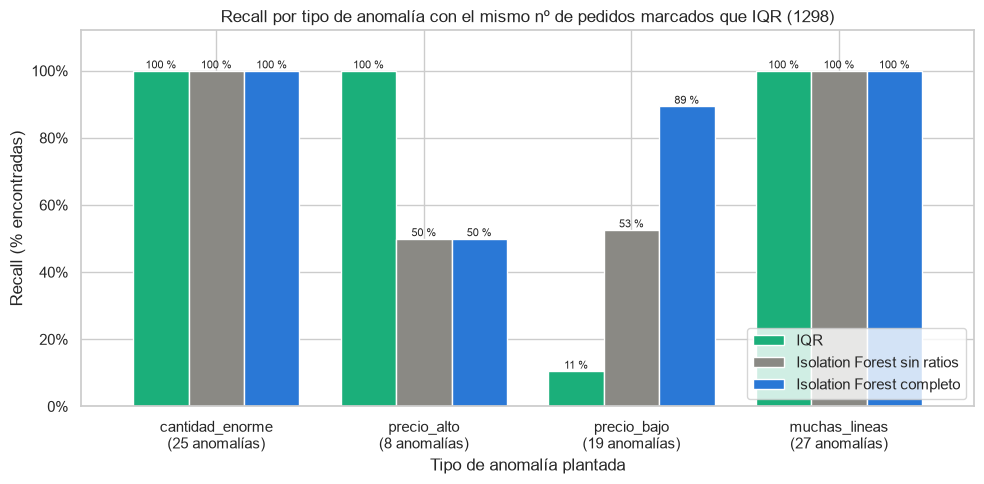

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
recalls = pd.DataFrame({
    "IQR": por_tipo["recall IQR"],
    "Isolation Forest sin ratios": por_tipo_ablacion[f"sin ratios (top {N_IQR})"],
    "Isolation Forest completo": por_tipo_ablacion[f"completo (top {N_IQR})"],
})
recalls.index = [f"{t}\n({n} anomalías)" for t, n in por_tipo["anomalías"].items()]
recalls.plot.bar(ax=ax, color=[VERDE_AGUA, GRIS, AZUL], rot=0, width=0.8)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[pct(v, 0) for v in contenedor.datavalues], fontsize=8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.12)
ax.set_xlabel("Tipo de anomalía plantada")
ax.set_ylabel("Recall (% encontradas)")
ax.set_title(f"Recall por tipo de anomalía con el mismo nº de pedidos marcados que IQR ({N_IQR})")
ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "recall_por_tipo")
plt.show()

**Lectura:** con el mismo número de pedidos marcados (121), quitar los ratios empeora todo:
recall del 79,7 % al 69,6 %, precision del 52,1 % al 45,5 %, F1 de 0,630 a 0,550, ROC-AUC de 0,968 a
0,928, **PR-AUC de 0,762 a 0,671** y precision@50 del 86 % al 82 %. Casi todo viene de los **precios
bajos**: con 121 alertas, el recall cae del 42,1 % al 5,3 %; con 1.298, del 89,5 % al 52,6 %. Su ranking
mediano pasa del 146 al 1.102. Los precios altos bajan del 37,5 % al 25 % con 121 alertas y se quedan en
50 % con 1.298. Cantidad enorme y muchas líneas no cambian (100 %): ya las delatan las unidades y las
líneas.

**Qué demuestra:** el algoritmo no inventa información. Un precio distinto del catálogo solo se puede
detectar si alguna variable **compara el precio con el catálogo**; sin ella, el modelo solo ve el efecto
indirecto en el importe por unidad. Crear la variable adecuada (una división en SQL) aporta más que
cualquier ajuste de hiperparámetros. Y los precios altos muestran el límite contrario: una variable que
casi nunca cambia (8 pedidos de 7.297) es difícil de usar para Isolation Forest, aunque sea la
adecuada.

## 9. Conclusiones

1. **Hay pedidos sospechosos y se pueden ordenar.** Isolation Forest da a cada pedido una puntuación
   de 0 a 1 (de 0,401 a 0,752) y un motivo con sus 2–3 variables más extremas.
2. **El umbral sale de las puntuaciones, no de llenar la capacidad:** Q3 + 1,5·IQR de las puntuaciones,
   s ≥ 0,614 → **121 pedidos (1,66 %), 5,0 al mes** (máximo 10). El tope de 50 al mes no se alcanza
   nunca. Los criterios que llenaban el tope (`contamination="auto"`, el codo de toda la curva) daban
   más de 1.000 pedidos.
3. **Con el mismo número de alertas (1.298), Isolation Forest supera a IQR:** 73 frente a 62 anomalías
   (recall del 92,4 % frente al 78,5 %, F1 de 0,106 frente a 0,090).
4. **Con el umbral elegido, una de cada dos alertas es real:** precision 52,1 %, recall 79,7 %, F1 0,630.
   Con la puntuación continua, ROC-AUC = 0,968 y PR-AUC = 0,762 (azar = 0,011). De los 50 primeros, 43
   son anomalías (precision@50 = 86,0 %).
5. **Por tipo (umbral elegido):** el 100 % de las cantidades enormes y de los pedidos con muchas líneas,
   pero solo el 42,1 % de los precios bajos y el 37,5 % de los altos. Las 16 que se escapan son todas de
   precio: el 75,5 % de los árboles no ve ningún pedido con el precio por encima del catálogo.
6. **Las variables importan más que el algoritmo:** sin los ratios de precio, la PR-AUC baja de 0,762 a
   0,671.
7. **Es estable:** con otras 5 semillas, el 92,6–95,9 % de los marcados coincide (Jaccard medio 0,897) y
   el umbral propio de cada una marca entre 109 y 121 pedidos.

**Respuesta a la pregunta de negocio:** son sospechosos los pedidos con muchas unidades de un mismo
producto, con muchas líneas o con una combinación rara de tamaño e importe; los precios lejos del
catálogo se detectan peor. `data/processed/pedidos_sospechosos.csv` da los **121 marcados** (unos 5 al
mes), ordenados por sospecha y con su motivo. Si sobra capacidad, se sigue bajando por el ranking.

**Trabajo futuro (no aplicado): un enfoque híbrido.** Se trata de usar reglas de negocio junto con el
modelo, por ejemplo "precio pagado > precio de catálogo → revisar" (y lo mismo por debajo). Solo 27
pedidos (0,37 %) tienen un precio distinto del de catálogo, así que la regla apenas añadiría trabajo y
cubriría las anomalías de precio que se le escapan al modelo. La idea surgió en la evaluación con la
verdad (secciones 7 y 8), así que no se ha aplicado: el modelo y el umbral se eligieron sin la verdad, y
cambiarlos ahora sería elegirlos con ella.